In [1]:
import hashlib, importlib, io, json, math, os, struct, subprocess, sys, time, zipfile
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor, as_completed
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from affine import Affine
from matplotlib.path import Path as PolyPath
from pyproj import CRS, Transformer
from rasterio.enums import MergeAlg
from rasterio.features import rasterize
from scipy import ndimage
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import spearmanr

assert Path.cwd().name == "ml", "run this notebook from the ml/ folder (the %%writefile cells write to ml/export/)"
ROOT = Path.cwd().parent                     # repo root
DATA, RAW, CACHE, EXPORT = ROOT / "data", ROOT / "ml" / "datasets", ROOT / "data" / "cache", ROOT / "ml" / "export"
for p in (RAW, CACHE, EXPORT):
    p.mkdir(parents=True, exist_ok=True)

LOCAL = dict(
    glo30_tiles=RAW / "glo30_tileList.txt",
    geology_moon=RAW / "geology" / "Unified_Geologic_Map_of_the_Moon_GIS_v2.zip",
    geology_mars=RAW / "geology" / "sim3292_database.zip",
    gazetteer_moon=RAW / "gazetteer" / "MOON_nomenclature_center_pts.zip",
    gazetteer_mars=RAW / "gazetteer" / "MARS_nomenclature_center_pts.zip",
    robbins_moon=RAW / "robbins" / "Catalog_Moon_Release_20180815_shapefile180.zip",
    robbins_mars=RAW / "robbins" / "Catalog_Mars_Release_2020_1kmPlus_FullMorphData.csv.zip",
    ctx_footprints=RAW / "stac" / "ctx_dtm_footprints.npz",
    analog_sites=ROOT / "ml" / "analog_sites.csv",          # sourced site list, built by hand + checked against documents
    earth_craters=ROOT / "ml" / "earth_craters.csv",        # USGS locations + Wikidata diameters
    lola_polar_site=RAW / "dem" / "LDEM_80S_20MPP_ADJ.TIF",
    lola_polar_regional=RAW / "dem" / "LDEM_80S_80MPP_ADJ.TIF",
    worldclim=RAW / "climate" / "wc2.1_10m_prec.zip",
    gvp=RAW / "gvp_holocene.json",
    lola_118m=RAW / "dem" / "Lunar_LRO_LOLA_Global_LDEM_118m_Mar2014.tif",                  # optional
    mola_hrsc=RAW / "dem" / "Mars_HRSC_MOLA_BlendDEM_Global_200mp_v2.tif",                 # optional
)


def need(key):
    p = LOCAL[key]
    if not p.exists():
        raise FileNotFoundError(f"{key}: put the file at {p} (see ml/data.md)")
    return p


PROFILE = os.environ.get("ANALOG_PROFILE", "v1")   # "smoke" (pipeline check) | "v1" (ships) | "full"
SIZES = {
    "smoke": dict(per_region=60, n_random_land=300, n_volcanoes=60, n_eval=60, n_boot=10),
    "v1": dict(per_region=600, n_random_land=2500, n_volcanoes=300, n_eval=150, n_boot=20),
    "full": dict(per_region=2000, n_random_land=20000, n_volcanoes=400, n_eval=200, n_boot=50),
}
MODEL_VERSION = f"regions-1.2-{PROFILE}"
CACHE_TAG = "r2"                  # bump when features or sampling change, so old caches aren't reused
SEED = 20261114
CFG = dict(
    **SIZES[PROFILE],                          # library blocks per region; Earth set sizes; eval blocks per region
    tag_share=0.5,                             # half of each region's blocks are placed on mapped landforms
    oversample={"moon": 3.5, "mars": 2.0},     # candidate locations per block kept (stripes, missing DTMs)
    max_per_feature=4 if PROFILE == "smoke" else 10,
    line_step_km=15.0,                         # spacing of candidate blocks along a mapped line
    stripe_max=0.18,                           # Kaguya blocks above this stripe score are rejected
    max_lat=86.5,                              # the global DEMs can't be windowed closer to a pole
    polar_lat=-80.0, polar_max_lat=89.0,       # Moon south of 80S reads polar LOLA instead, which works to the pole
    site_max_nodata=0.05,                      # share of no-data allowed in a 4 km window (filled)
    ctx_inset_km=4.5,                          # a Mars point must sit this far inside a CTX footprint
    min_crater_km=1.0,                         # Earth craters smaller than this are too small for a 4 km block
    crater_min_relief=30.0,                    # Earth crater blocks flatter than this (m) are buried or eroded: dropped
    cover_max=0.3, snap_km=6.0,                # analog sites with more tree/crop/built/water than this get nudged
    discount_floor=0.0,                        # overall = landscape x (floor + (1 - floor) x conditions). 0.4 let farmland through
    workers=24,
    shortlist=100, top_k=25,                   # per region and scale: match 100 blocks, average the best 25
    n_segments=10, lam_s_grid=(0.1, 1.0, 10.0), lam_r=1e-3,
    folds=5, pos_per_block=6, max_anchors=4000,
    cross_weight=0.0,                          # Earth-to-planet triplets made both transfer tests worse in 1.1, so they're off
    drop={"site": ("rough_coarse",), "regional": ()},   # features ignored per scale (the tokens stay the same, so caches survive)
    site_share_min=0.4,                        # the 4 km scale gets at least this share of the landscape score
    score_workers=8,                           # processes used to score the Earth blocks
)
SCALES = ("site", "regional")
WORLDS = ("moon", "mars")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print(PROFILE, "profile | model", MODEL_VERSION)

v1 profile | model regions-1.2-v1


In [2]:
%%writefile export/analog_runtime.py
from __future__ import annotations

import math

import numpy as np
from scipy import ndimage
from scipy.optimize import linear_sum_assignment
from scipy.special import expit

#  grid and constants

SCALES = {   # the same feature code runs at both scales; everything below is in pixels
    "site": dict(res=31.25, flat_deg=1.0, sun_low=1.5, sun_mid=10.0),
    "regional": dict(res=250.0, flat_deg=0.25, sun_low=1.0, sun_mid=4.0),
}
BLOCK_PX = 128                      # the block: 4 km (site) or 32 km (regional)
PAD_PX = 64                         # margin on every side, for shadows cast from outside the block
WINDOW_PX = BLOCK_PX + 2 * PAD_PX   # 256 px padded window
CELL_PX = 16                        # 8 x 8 = 64 cells (tokens) per block
LOWPASS_PX = 1.0                    # the same Gaussian blur on every world: one effective resolution
ROUGH_FINE_PX, ROUGH_COARSE_PX, TPI_PX = 3, 11, 39      # filter window widths
SHADOW_PX, SVF_PX = 64, 32          # horizon search distances
RADIUS_M = {"earth": 6_371_000.0, "moon": 1_737_400.0, "mars": 3_396_190.0}
WORLDS = ("moon", "mars")

# v1.1: 13 -> 7 token features. dropped the ones that mostly measure DEM noise (rough_fine, curv) and the
# near-duplicates (slope_p90, cell_relief, svf ~ slope_mean; geo_flat = 1 - convex - concave). see ml/diag.ipynb
TOKEN_FEATURES = (
    "slope_mean", "rough_coarse", "geo_convex", "geo_concave",
    "shadow_low", "shadow_mid", "norm_height",
)
BLOCK_FEATURES = ("relief", "hurst", "linearity", "depression_area", "depression_depth")   # hypsometry ~ norm_height
INPUT_NAMES = TOKEN_FEATURES + tuple("d_" + b for b in BLOCK_FEATURES)
N_TOK, N_IN = len(TOKEN_FEATURES), len(TOKEN_FEATURES) + len(BLOCK_FEATURES)
ENV_NAMES = ("tree", "crop", "built", "water", "snow", "bare", "precip")     # what the readers return for a click
GATE_NAMES = ("tree", "crop", "built", "water", "open", "precip")             # what the conditions model sees
GRID = np.linspace(0.0, 1.0, 1001)
QUANTILES = (np.arange(8) + 0.5) / 8

# 8 azimuths as (row step, col step). Row 0 is north. Closed under 90 degree rotation and mirroring.
DIRS = ((0, 1), (-1, 1), (-1, 0), (-1, -1), (0, -1), (1, -1), (1, 0), (1, 1))


#  terrain features (no training)

def fill_nans(z: np.ndarray) -> np.ndarray:
    bad = np.isnan(z)
    if not bad.any():
        return z
    if bad.all():
        raise ValueError("window has no valid pixels")
    idx = ndimage.distance_transform_edt(bad, return_distances=False, return_indices=True)
    return z[tuple(idx)]


def detrend(z: np.ndarray) -> np.ndarray:
    # Remove the best-fit plane, so a regional tilt doesn't count as texture.
    n = z.shape[0]
    yy, xx = np.mgrid[0:n, 0:n] - (n - 1) / 2.0
    A = np.c_[xx.ravel(), yy.ravel(), np.ones(n * n)]
    return z - (A @ np.linalg.lstsq(A, z.ravel(), rcond=None)[0]).reshape(n, n)


def stripe_score(z_block: np.ndarray, n_bins: int = 18) -> float:
    n = z_block.shape[0]
    w = np.hanning(n)
    P = np.abs(np.fft.fftshift(np.fft.fft2(detrend(z_block) * w[:, None] * w[None, :]))) ** 2
    ky, kx = np.mgrid[0:n, 0:n] - n // 2
    k = np.hypot(kx, ky)
    m = (k >= n / 8) & (k < n / 2)                      # wavelengths of 2 to 8 pixels
    b = np.minimum(((np.degrees(np.arctan2(ky, kx)) % 180) / (180 / n_bins)).astype(int), n_bins - 1)
    e = np.bincount(b[m], weights=P[m], minlength=n_bins)
    return float(e.max() / max(e.sum(), 1e-30))


def slope_deg(z: np.ndarray, res: float) -> np.ndarray:
    gy, gx = np.gradient(z, res)
    return np.degrees(np.arctan(np.hypot(gx, gy)))


def horizon_tangents(z, res, pad, radius_m):
    n = z.shape[0] - 2 * pad
    c = z[pad:pad + n, pad:pad + n]
    far, near = np.empty((8, n, n)), np.empty((8, n, n))
    for a, (dr, dc) in enumerate(DIRS):
        step = math.hypot(dr, dc)
        kmax = min(int(SHADOW_PX // step), pad)
        best = np.full((n, n), -np.inf)
        best_near = np.full((n, n), -np.inf)
        for k in range(1, kmax + 1):
            d = k * step * res
            s = z[pad + k * dr: pad + k * dr + n, pad + k * dc: pad + k * dc + n]
            t = (s - c - d * d / (2.0 * radius_m)) / d
            np.maximum(best, t, out=best)
            if k * step <= SVF_PX:
                np.maximum(best_near, t, out=best_near)
        far[a], near[a] = best, best_near
    return far, near


def hurst_exponent(z: np.ndarray) -> float:
    lags = np.array([1, 2, 4, 8, 16, 32])
    gam = []
    for L in lags:
        dx = z[:, L:] - z[:, :-L]
        dy = z[L:, :] - z[:-L, :]
        gam.append(0.25 * (np.mean(dx * dx) + np.mean(dy * dy)))
    gam = np.maximum(np.array(gam), 1e-12)
    return float(np.polyfit(np.log(lags), np.log(gam), 1)[0] / 2.0)


def depressions(z: np.ndarray, pad: int, relief: float):
    f = 4
    n = z.shape[0] // f
    zc = z[:n * f, :n * f].reshape(n, f, n, f).mean(axis=(1, 3))
    filled = np.full_like(zc, zc.max())
    filled[0, :], filled[-1, :], filled[:, 0], filled[:, -1] = zc[0, :], zc[-1, :], zc[:, 0], zc[:, -1]
    for _ in range(4 * n):
        nxt = np.maximum(zc, ndimage.minimum_filter(filled, size=3, mode="nearest"))
        if np.array_equal(nxt, filled):
            break
        filled = nxt
    p = pad // f
    depth = (filled - zc)[p:n - p, p:n - p]
    rel = max(relief, 1e-6)
    return float((depth > 0.03 * rel).mean()), float(min(depth.mean() / rel, 1.0))


def layout_features(zc: np.ndarray, z: np.ndarray, pad: int, relief: float):
    # Block-level shape numbers the cell matching cannot see (it compares cells as an unordered set).
    gy, gx = np.gradient(detrend(zc))
    jxx, jyy, jxy = (gx * gx).mean(), (gy * gy).mean(), (gx * gy).mean()
    linearity = math.sqrt((jxx - jyy) ** 2 + 4 * jxy * jxy) / max(jxx + jyy, 1e-12)   # 0 = no grain, 1 = one direction
    p2 = np.percentile(zc, 2)
    hyps = float(np.clip((zc.mean() - p2) / max(relief, 1e-6), 0.0, 1.0))             # low = flat floor with peaks
    dep_area, dep_depth = depressions(z, pad, relief)
    return float(linearity), hyps, dep_area, dep_depth


def to_cells(a: np.ndarray, cell_px: int) -> np.ndarray:
    # (H, H) map -> (n_cells, cell_px^2), cells in row-major order (cell index = i * n + j).
    n = a.shape[0] // cell_px
    return a.reshape(n, cell_px, n, cell_px).transpose(0, 2, 1, 3).reshape(n * n, cell_px * cell_px)


def compute_features(z_padded: np.ndarray, radius_m: float, scale: str = "site", return_maps: bool = False):
    cfg = SCALES[scale]
    res, pad, cell_px = cfg["res"], PAD_PX, CELL_PX
    z = ndimage.gaussian_filter(fill_nans(np.asarray(z_padded, dtype=np.float64)), LOWPASS_PX, mode="nearest")
    n = z.shape[0] - 2 * pad

    def crop(a):
        return a[pad:pad + n, pad:pad + n]

    slope = crop(slope_deg(z, res))
    rc = crop(z - ndimage.uniform_filter(z, ROUGH_COARSE_PX, mode="nearest"))

    tpi = crop(z - ndimage.uniform_filter(z, TPI_PX, mode="nearest"))
    thr = 0.5 * (TPI_PX // 2) * res * np.tan(np.radians(cfg["flat_deg"]))
    flat = (np.abs(tpi) < thr).astype(float)
    convex = (tpi >= thr).astype(float)
    concave = (tpi <= -thr).astype(float)

    far, near = horizon_tangents(z, res, pad, radius_m)
    shadow_low = (far > np.tan(np.radians(cfg["sun_low"]))).mean(axis=0)
    shadow_mid = (far > np.tan(np.radians(cfg["sun_mid"]))).mean(axis=0)
    svf = 1.0 - np.sin(np.arctan(np.maximum(near, 0.0))).mean(axis=0)

    zc = crop(z)
    p2, p98 = np.percentile(zc, [2, 98])
    relief = p98 - p2

    S, RC, CV, CC, SL, SM, ZC = (to_cells(a, cell_px) for a in (slope, rc, convex, concave, shadow_low, shadow_mid, zc))
    tokens = np.stack([
        S.mean(1),
        np.sqrt((RC ** 2).mean(1)),
        CV.mean(1), CC.mean(1),
        SL.mean(1),
        SM.mean(1),
        (ZC.mean(1) - p2) / max(relief, 1.0),
    ], axis=1)
    linearity, _, dep_area, dep_depth = layout_features(zc, z, pad, relief)
    block = np.array([relief, hurst_exponent(zc), linearity, dep_area, dep_depth])
    if return_maps:
        return tokens, block, dict(dem=zc, slope=slope, tpi=tpi, shadow_low=shadow_low, svf=svf)
    return tokens, block


#  sketches and matching (no training)

def sketch_raw(tokens_scaled: np.ndarray) -> np.ndarray:
    q = np.quantile(tokens_scaled, QUANTILES, axis=-2)
    q = np.moveaxis(q, 0, -2) / np.sqrt(len(QUANTILES))
    return q.reshape(*q.shape[:-2], -1)


def block_diff(bu: np.ndarray, BV: np.ndarray) -> np.ndarray:
    # Block-level mismatches: |log relief ratio|, then plain absolute differences.
    BV = np.atleast_2d(BV)
    d = np.abs(BV - bu[None, :])
    d[:, 0] = np.abs(np.log1p(np.maximum(BV[:, 0], 0.0)) - math.log1p(max(bu[0], 0.0)))
    return d


def pair_inputs_many(U: np.ndarray, V: np.ndarray, bu: np.ndarray, BV: np.ndarray):
    V = np.asarray(V, dtype=np.float64)
    C = (U * U).sum(1)[None, :, None] + (V * V).sum(2)[:, None, :] - 2.0 * np.einsum("if,sjf->sij", U, V)
    raw = np.empty((len(V), N_IN))
    partner = np.empty((len(V), U.shape[0]), dtype=np.int64)
    for s in range(len(V)):
        _, c = linear_sum_assignment(C[s])
        d = U - V[s][c]
        raw[s, :N_TOK] = (d * d).mean(axis=0)
        partner[s] = c
    raw[:, N_TOK:] = block_diff(bu, BV)
    return raw, raw[:, :N_TOK].sum(1), partner


#  the trained model

class Model:
    # everything in model.npz, plus a few derived lookups

    def __init__(self, z: dict):
        self.z = z
        self.version = str(z["version"])
        self.scales = [str(s) for s in z["scales"]]
        self.S = {}
        for s in self.scales:
            g = lambda k, s=s: z[f"{s}__{k}"]
            self.S[s] = dict(
                scale=g("scaler_scale"), pca_mean=g("pca_mean"), pca_comp=g("pca_components"),
                pct_table=g("pct_table"), curve=g("curve_vals"), bias=float(g("bias")),
                ens_curve=g("ens_curve_vals"), ens_bias=g("ens_bias"),
                tokens=g("lib_tokens"),                       # (N, 64, N_TOK) scaled, float16 on disk
                block=g("lib_block").astype(np.float64), sketch=g("lib_sketch").astype(np.float64),
                earth_sketch=g("earth_sketch"), ood_threshold=float(g("ood_threshold")),
                weight=float(g("combo_weight")),
            )
        # library: one row per Moon or Mars location, with tokens at every scale
        self.lib_world = z["lib_world"]
        self.lib_region = z["lib_region"]                     # index into region_keys
        self.lib_tag, self.lib_name = z["lib_tag"], z["lib_name"]
        self.lib_lat, self.lib_lon, self.lib_href = z["lib_lat"], z["lib_lon"], z["lib_href"]
        self.region_keys = [str(s) for s in z["region_keys"]]       # "moon:maria", ...
        self.region_title = [str(s) for s in z["region_title"]]
        self.region_world = [k.split(":")[0] for k in self.region_keys]
        self.members = [np.flatnonzero(self.lib_region == r) for r in range(len(self.region_keys))]
        self.calib = {s: [np.sort(z[f"{s}__calib__{r}"]) for r in range(len(self.region_keys))] for s in self.scales}
        self.combo_bias = float(z["combo_bias"])
        self.top_k, self.shortlist = int(z["top_k"]), int(z["shortlist"])
        # Earth-side conditions; they can only discount the landscape score
        self.gate_names = [str(s) for s in z["gate_names"]]
        self.gate_table, self.gate_curve = z["gate_table"], z["gate_curve_vals"]
        self.gate_bias = float(z["gate_bias"])
        self.discount_floor = float(z["discount_floor"])
        self.precip = z["precip_grid"]                        # mm per year, row 0 = 90 N, col 0 = 180 W


def load(path) -> Model:
    with np.load(path, allow_pickle=False) as f:
        return Model({k: f[k] for k in f.files})


def precip_at(model: Model, lat: float, lon: float) -> float:
    # Mean annual precipitation (mm) from the small grid inside the model file. NaN where unknown.
    g = model.precip
    i = min(max(int((90.0 - lat) / 180.0 * g.shape[0]), 0), g.shape[0] - 1)
    j = min(max(int(((lon + 180.0) % 360.0) / 360.0 * g.shape[1]), 0), g.shape[1] - 1)
    v = float(g[i, j])
    return float("nan") if v >= 65535 else v


def top_k_for(model: Model, n_members: int) -> int:
    return max(3, min(model.top_k, n_members // 4))


def embed(model: Model, dems: dict, radius_m: float) -> dict:
    # {scale: padded DEM} -> {scale: (scaled tokens, block features, sketch)}.
    out = {}
    for s in model.scales:
        if dems.get(s) is None:
            continue
        P = model.S[s]
        tok_raw, blk = compute_features(dems[s], radius_m, s)
        tok = tok_raw / P["scale"]
        out[s] = (tok, blk, (sketch_raw(tok) - P["pca_mean"]) @ P["pca_comp"].T)
    if not out:
        raise ValueError("no DEM given")
    return out


def to_z(table: np.ndarray, raw: np.ndarray) -> np.ndarray:
    # raw (n, F) -> percentiles (n, F) in [0, 1] using per-input quantile tables (F, 1001).
    raw = np.atleast_2d(raw)
    return np.stack([np.interp(raw[:, k], table[k], GRID) for k in range(raw.shape[1])], axis=1)


def curves_at(curve_vals: np.ndarray, Z: np.ndarray) -> np.ndarray:
    # Curve values (n, F) for percentiles Z (n, F); curves are tabulated on GRID.
    return np.stack([np.interp(Z[:, k], GRID, curve_vals[k]) for k in range(Z.shape[1])], axis=1)


def pair_logit(model: Model, scale: str, raw: np.ndarray, ensemble: bool = False):
    # Pair model of one scale: (logit (n,), contributions (n, 19)[, ensemble logits (n, E)]).
    P = model.S[scale]
    Z = to_z(P["pct_table"], raw)
    contrib = curves_at(P["curve"], Z)
    lg = P["bias"] + contrib.sum(1)
    if not ensemble:
        return lg, contrib
    ens = np.stack([b + curves_at(cv, Z).sum(1) for cv, b in zip(P["ens_curve"], P["ens_bias"])], axis=1)
    return lg, contrib, ens


def calibrated(calib_sorted: np.ndarray, A: float, drop_self: float | None = None) -> float:
    n = len(calib_sorted)
    below = np.searchsorted(calib_sorted, A, side="right")
    if drop_self is not None:            # evaluation only: remove the query's own entry
        n -= 1
        below -= int(drop_self <= A)
    return float((below + 0.5) / (n + 1))


def to_logit(score_0_100: float) -> float:
    p = min(max(score_0_100 / 100.0, 0.02), 0.98)
    return float(np.log(p / (1 - p)))


def region_scores(model: Model, emb: dict, world: str, exclude: np.ndarray | None = None,
                  n_best: int = 3, with_cells: bool = False):
    out = []
    for r, key in enumerate(model.region_keys):
        if model.region_world[r] != world:
            continue
        mem = model.members[r]
        if exclude is not None:
            mem = mem[~exclude[mem]]
        if len(mem) < 4:
            continue
        k = top_k_for(model, len(mem))
        per_scale, cand, w_sum, L = {}, {}, 0.0, model.combo_bias
        for s, (tok, blk, sk) in emb.items():
            P = model.S[s]
            short = mem[np.argsort(((P["sketch"][mem] - sk) ** 2).sum(1))[:model.shortlist]]
            raw, W, partner = pair_inputs_many(tok, P["tokens"][short], blk, P["block"][short])
            lg, contrib = pair_logit(model, s, raw)
            A = float(np.sort(lg)[::-1][:k].mean())
            score = 100.0 * calibrated(model.calib[s][r], A)
            per_scale[s] = dict(score=score, aggregate=A)
            cand[s] = dict(short=short, lg=lg, contrib=contrib, W=W, partner=partner, raw=raw)
            L += P["weight"] * to_logit(score)
            w_sum += P["weight"]
        w_all = sum(model.S[s]["weight"] for s in model.scales)
        if 0 < w_sum < w_all:             # a scale is missing: the others carry its weight
            L = model.combo_bias + (L - model.combo_bias) * w_all / w_sum

        lead = "site" if "site" in cand else next(iter(cand))
        c0 = cand[lead]
        top = np.argsort(-c0["lg"])[:max(30, n_best)]        # the 30 best at the lead scale are re-ranked with every scale
        joint = c0["lg"][top].copy()
        others = {}
        for s in emb:
            if s == lead:
                continue
            tok, blk, _ = emb[s]
            P = model.S[s]
            raw_o, _, _ = pair_inputs_many(tok, P["tokens"][c0["short"][top]], blk, P["block"][c0["short"][top]])
            others[s] = pair_logit(model, s, raw_o)[0]
            joint = joint + others[s]
        joint = joint / (1 + len(others))
        best = []
        for o in np.argsort(-joint)[:n_best]:
            i = top[o]
            j = int(c0["short"][i])
            b = dict(index=j, name=str(model.lib_name[j]), tag=str(model.lib_tag[j]), region=key,
                     lat=float(model.lib_lat[j]), lon=float(model.lib_lon[j]), href=str(model.lib_href[j]),
                     pair_score=float(100 * expit(joint[o])), logit=float(joint[o]),
                     scale_logits={lead: float(c0["lg"][i]), **{s: float(v[o]) for s, v in others.items()}},
                     W=float(c0["W"][i]),
                     contributions={n: float(v) for n, v in zip(INPUT_NAMES, c0["contrib"][i])})
            if with_cells:
                tok = emb[lead][0]
                d = tok - model.S[lead]["tokens"][j].astype(np.float64)[c0["partner"][i]]
                b["cell_cost"] = (d * d).sum(1).reshape(8, 8).tolist()
                b["partner"] = c0["partner"][i].tolist()
            best.append(b)
        out.append(dict(region_id=r, region=key, title=model.region_title[r], score=float(100 * expit(L)),
                        logit=float(L), scales=per_scale, n_members=int(len(mem)), best=best))
    out.sort(key=lambda d: -d["score"])
    return out


def gate_inputs(env: dict, names=GATE_NAMES) -> np.ndarray:
    # conditions inputs from the raw land-cover shares. "open" = bare ground + snow and ice: neither hides the
    # terrain, so snow isn't penalised (polar analogs like the Dry Valleys are mostly snow, ice and bare rock)
    e = {k: float(v) for k, v in env.items()}
    bare = e.get("bare", np.nan)
    e["open"] = np.nan if np.isnan(bare) else bare + float(np.nan_to_num(e.get("snow", 0.0)))
    return np.array([e.get(n, np.nan) for n in names], dtype=float)


def conditions(model: Model, env: dict):
    # Earth-side conditions: (logit, {input: contribution in logit points}). One-sided curves.
    x = gate_inputs(env, model.gate_names)
    Z = to_z(model.gate_table, np.nan_to_num(x, nan=0.0)[None, :])[0]
    Z[np.isnan(x)] = 0.5                 # missing -> typical land
    h = np.array([np.interp(Z[m], GRID, model.gate_curve[m]) for m in range(len(x))])
    return float(model.gate_bias + h.sum()), {n: float(v) for n, v in zip(model.gate_names, h)}


def score_click(model: Model, dems: dict, env: dict, worlds=WORLDS, n_best: int = 3) -> dict:
    # Everything the API returns for one Earth click: one entry per world (the two tabs).
    emb = embed(model, dems, RADIUS_M["earth"])
    G, terms = conditions(model, env)
    ood = {s: bool(np.sqrt(((model.S[s]["earth_sketch"] - emb[s][2]) ** 2).sum(1).min()) > model.S[s]["ood_threshold"])
           for s in emb}
    blk = emb["site"][1] if "site" in emb else next(iter(emb.values()))[1]
    cond = float(100 * expit(G))
    discount = model.discount_floor + (1.0 - model.discount_floor) * cond / 100.0
    out = dict(model_version=model.version, scales_used=list(emb), ood=any(ood.values()), ood_by_scale=ood,
               conditions=dict(score=cond, logit=G, terms=terms, discount=discount),
               block={n: float(v) for n, v in zip(BLOCK_FEATURES, blk)}, worlds={})
    for w in worlds:
        regs = region_scores(model, emb, w, n_best=n_best, with_cells=True)
        for reg in regs:
            reg["overall"] = float(reg["score"] * discount)      # landscape always counts; conditions only lower it
        regs.sort(key=lambda d: -d["overall"])
        best = max((b for reg in regs for b in reg["best"]), key=lambda b: b["logit"])
        out["worlds"][w] = dict(regions=regs, best_region=regs[0]["region"], landscape_score=regs[0]["score"],
                                overall=regs[0]["overall"], best_match=best)
    return out


_WORKER_MODELS = {}


def region_logits_task(args):
    # (model path, embedding) -> (region logits (R,), per-scale scores (R, n_scales)). for process pools: the
    # notebook scores thousands of Earth blocks with it; the server doesn't need it
    path, emb = args
    m = _WORKER_MODELS.get(path)
    if m is None:
        m = _WORKER_MODELS[path] = load(path)
    logit = np.full(len(m.region_keys), np.nan)
    per = np.full((len(m.region_keys), len(m.scales)), np.nan)
    for w in WORLDS:
        for reg in region_scores(m, emb, w, n_best=1):
            logit[reg["region_id"]] = reg["logit"]
            per[reg["region_id"]] = [reg["scales"].get(s, {}).get("score", np.nan) for s in m.scales]
    return logit, per


Overwriting export/analog_runtime.py


In [3]:
%%writefile export/analog_readers.py
#most things here will be fetched with a s3 bucket 
from __future__ import annotations

import ssl
import time
import urllib.request

import numpy as np
import rasterio
import rasterio.enums
import rasterio.windows
from pyproj import CRS, Transformer
from scipy import ndimage

import analog_runtime as rt

GDAL_ENV = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.TIF",
                GDAL_HTTP_MULTIPLEX="YES", GDAL_HTTP_MULTIRANGE="YES", GDAL_HTTP_MERGE_CONSECUTIVE_RANGES="YES",
                GDAL_HTTP_MAX_RETRY="3", GDAL_HTTP_RETRY_DELAY="1", VSI_CACHE="TRUE", VSI_CACHE_SIZE="67108864")
GLO30 = "https://copernicus-dem-30m.s3.amazonaws.com"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map"
GLOBAL_DEM = {   # the regional scale on the Moon and Mars (library building only)
    "moon": "/vsicurl/https://planetarymaps.usgs.gov/mosaic/Lunar_LRO_LOLA_Global_LDEM_118m_Mar2014.tif",
    "mars": "/vsicurl/https://planetarymaps.usgs.gov/mosaic/Mars/HRSC_MOLA_Blend/Mars_HRSC_MOLA_BlendDEM_Global_200mp_v2.tif",
}
POLAR_DEM = {   # Moon south of 80S: polar stereographic LOLA, readable all the way to the pole
    "site": "https://pgda.gsfc.nasa.gov/data/LOLA_20mpp/LDEM_80S_20MPP_ADJ.TIF",
    "regional": "https://pgda.gsfc.nasa.gov/data/LOLA_20mpp/LDEM_80S_80MPP_ADJ.TIF",
}
POLAR_LAT = -80.0
UA = "Mozilla/5.0 (analog-explorer)"
WC = {10: "tree", 20: "shrub", 30: "grass", 40: "crop", 50: "built", 60: "bare", 70: "snow",
      80: "water", 90: "wetland", 95: "mangrove", 100: "moss"}
WC_NAMES = ("tree", "crop", "built", "water", "snow", "bare")
_TILES = None


def http(url, body=None, timeout=60, tries=3, headers=None):
    ctx = ssl.create_default_context()
    try:
        import certifi
        ctx = ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        pass
    for t in range(tries):
        try:
            hdr = {"User-Agent": UA, **({"Content-Type": "application/json"} if body else {}), **(headers or {})}
            with urllib.request.urlopen(urllib.request.Request(url, data=body, headers=hdr), context=ctx, timeout=timeout) as r:
                return r.read()
        except Exception:
            if t == tries - 1:
                raise
            time.sleep(1 + 2 * t)


# ---------------------------------------------------------------- the common local grid

def window_lonlat(lat, lon, R, res, n_px=rt.WINDOW_PX):
    c = (np.arange(n_px) - (n_px - 1) / 2) * res
    X, Y = np.meshgrid(c, -c)            # x east, y north; row 0 is north
    aeqd = CRS.from_proj4(f"+proj=aeqd +lat_0={lat} +lon_0={lon} +R={R} +units=m +no_defs")
    geo = CRS.from_proj4(f"+proj=longlat +R={R} +no_defs")
    return Transformer.from_crs(aeqd, geo, always_xy=True).transform(X, Y)


def read_raster_window(href, lat, lon, R, res, max_nodata=0.02):
    lon_g, lat_g = window_lonlat(lat, lon, R, res)
    with rasterio.Env(**GDAL_ENV), rasterio.open(href) as ds:
        crs = CRS.from_wkt(ds.crs.to_wkt())
        if crs.is_projected:
            xs, ys = Transformer.from_crs(crs.geodetic_crs, crs, always_xy=True).transform(lon_g, lat_g)
            native = abs(ds.res[0])
        else:
            xs, ys = lon_g, lat_g
            if ds.bounds.right > 180.5:                      # a 0..360 raster
                xs = np.mod(xs, 360.0)
            native = abs(ds.res[1]) * np.pi / 180.0 * R
        cols, rows = ~ds.transform * (xs, ys)
        cols, rows = np.asarray(cols) - 0.5, np.asarray(rows) - 0.5        # pixel-centre coordinates
        c0, c1 = int(np.floor(cols.min())) - 3, int(np.ceil(cols.max())) + 4
        r0, r1 = int(np.floor(rows.min())) - 3, int(np.ceil(rows.max())) + 4
        if c0 < 0 or r0 < 0 or c1 > ds.width or r1 > ds.height:
            raise ValueError("window leaves the raster")
        if (c1 - c0) > 0.4 * ds.width or (c1 - c0) * (r1 - r0) > 30_000_000:
            raise ValueError("window crosses the map edge or is too close to a pole")
        a = ds.read(1, window=rasterio.windows.Window(c0, r0, c1 - c0, r1 - r0), masked=True)
    z = a.astype(np.float64).filled(np.nan)
    z[z < -30000] = np.nan
    bad = ndimage.map_coordinates(np.isnan(z).astype(float), [rows - r0, cols - c0], order=1, mode="nearest")
    if (bad > 0.5).mean() > max_nodata:
        raise ValueError("too much nodata")
    z = rt.fill_nans(z)
    factor = res / native
    if factor > 1.2:
        z = ndimage.gaussian_filter(z, 0.5 * factor)
    return ndimage.map_coordinates(z, [rows - r0, cols - c0], order=1, mode="nearest"), native


#  Earth terrain: Copernicus GLO-30

def glo30_tile_name(la, lo):
    return f"Copernicus_DSM_COG_10_{'N' if la >= 0 else 'S'}{abs(la):02d}_00_{'E' if lo >= 0 else 'W'}{abs(lo):03d}_00_DEM"


def glo30_tiles(cache_path=None):
    # Names of the tiles that exist (land). Fetched once; pass cache_path to keep a local copy.
    global _TILES
    if _TILES is None:
        if cache_path is not None and cache_path.exists():
            text = cache_path.read_text()
        else:
            text = http(f"{GLO30}/tileList.txt").decode()
            if cache_path is not None:
                cache_path.write_text(text)
        _TILES = {s.strip() for s in text.splitlines() if s.strip()}
    return _TILES


def read_glo30_window(lat, lon, res):
    R = rt.RADIUS_M["earth"]
    lon_g, lat_g = window_lonlat(lat, lon, R, res)
    lon_g = (lon_g + 180.0) % 360.0 - 180.0
    out = np.full(lon_g.shape, np.nan)
    lat_f, lon_f = np.floor(lat_g).astype(int), np.floor(lon_g).astype(int)
    tiles = glo30_tiles()
    with rasterio.Env(**GDAL_ENV):
        for la, lo in {(int(a), int(b)) for a, b in zip(lat_f.ravel(), lon_f.ravel())}:
            name = glo30_tile_name(la, lo)
            if name not in tiles:
                continue
            sel = (lat_f == la) & (lon_f == lo)
            with rasterio.open(f"/vsicurl/{GLO30}/{name}/{name}.tif") as ds:
                dx, dy = ds.res
                w = rasterio.windows.from_bounds(lon_g[sel].min() - 9 * dx, lat_g[sel].min() - 9 * dy,
                                                 lon_g[sel].max() + 9 * dx, lat_g[sel].max() + 9 * dy, ds.transform)
                w = w.round_offsets().round_lengths().intersection(rasterio.windows.Window(0, 0, ds.width, ds.height))
                native_m = dy * np.pi / 180.0 * R
                f = max((k for k in (1, 2, 4, 8) if k * native_m <= res), default=1)   # overview level
                shape = (max(1, int(round(w.height / f))), max(1, int(round(w.width / f))))
                arr = ds.read(1, window=w, out_shape=shape, resampling=rasterio.enums.Resampling.average).astype(np.float64)
                t = ds.window_transform(w)
            sx, sy = t.a * w.width / shape[1], t.e * w.height / shape[0]          # degrees per decimated pixel
            factor = res / (abs(sy) * np.pi / 180.0 * R)
            if factor > 1.2:
                arr = ndimage.gaussian_filter(arr, 0.5 * factor, mode="nearest")
            col = (lon_g[sel] - t.c) / sx - 0.5
            row = (lat_g[sel] - t.f) / sy - 0.5
            out[sel] = ndimage.map_coordinates(arr, [row, col], order=1, mode="nearest")
    return out


def flat_fraction(z):
    # Share of pixels identical to both neighbours: GLO-30 flattens water bodies.
    same = (z[:-1, :-1] == z[:-1, 1:]) & (z[:-1, :-1] == z[1:, :-1])
    return float(same.mean())


#  Earth surface: ESA WorldCover 2021

def worldcover_shares(lat, lon, half_m=2000.0):
    # Land-cover shares over the 4 km block: tree, crop, built, water, snow, bare. NaN when unknown.
    dlat = np.degrees(half_m / rt.RADIUS_M["earth"])
    dlon = dlat / max(np.cos(np.radians(lat)), 1e-3)
    la0, lo0 = int(np.floor(lat / 3) * 3), int(np.floor(lon / 3) * 3)
    name = f"ESA_WorldCover_10m_2021_v200_{'N' if la0 >= 0 else 'S'}{abs(la0):02d}{'E' if lo0 >= 0 else 'W'}{abs(lo0):03d}_Map.tif"
    try:
        with rasterio.Env(**GDAL_ENV), rasterio.open(f"/vsicurl/{WORLDCOVER}/{name}") as ds:
            w = rasterio.windows.from_bounds(lon - dlon, lat - dlat, lon + dlon, lat + dlat, ds.transform)
            w = w.round_offsets().round_lengths().intersection(rasterio.windows.Window(0, 0, ds.width, ds.height))
            a = ds.read(1, window=w)
    except Exception:
        if lat < -60.0:                                # WorldCover has no Antarctic tiles; down there it's ice or bare rock
            return dict(tree=0.0, crop=0.0, built=0.0, water=0.0, snow=1.0, bare=0.0)
        return {n: np.nan for n in WC_NAMES}           # no tile (ocean edge, outside coverage): unknown
    a = a[a > 0]
    if a.size == 0:
        return {n: np.nan for n in WC_NAMES}
    s = {name: float(np.mean(a == k)) for k, name in WC.items()}
    return dict(tree=s["tree"] + s["mangrove"], crop=s["crop"], built=s["built"],
                water=s["water"] + s["wetland"], snow=s["snow"], bare=s["bare"])


#  one click, start to finish

def fetch_earth(model, lat, lon, scales=None):
    # Everything score_click needs for an Earth coordinate: ({scale: padded DEM}, env dict).
    dems = {s: read_glo30_window(lat, lon, rt.SCALES[s]["res"]) for s in (scales or model.scales)}
    site = dems.get("site", next(iter(dems.values())))
    if np.isnan(site).mean() > 0.5 or flat_fraction(np.nan_to_num(site, nan=-1e9)) > 0.5:
        raise ValueError("no_terrain: the block is mostly ocean, lake or missing data")
    for s in list(dems):
        if np.isnan(dems[s]).mean() > 0.6:
            del dems[s]                                  # e.g. a small island: no regional context
    env = worldcover_shares(lat, lon)
    env["precip"] = rt.precip_at(model, lat, lon)
    return dems, env


def score_latlon(model, lat, lon, **kw):
    dems, env = fetch_earth(model, lat, lon)
    out = rt.score_click(model, dems, env, **kw)
    out["env"] = env
    return out


def library_block_dem(model, index, scale="site"):
    # The matched Moon or Mars block as a (128, 128) height grid, read from its source DEM (about 1 s).
    world, lat = str(model.lib_world[index]), float(model.lib_lat[index])
    href = str(model.lib_href[index]) if scale == "site" else GLOBAL_DEM[world]
    if scale != "site" and world == "moon" and lat <= POLAR_LAT:
        href = POLAR_DEM[scale]
    dem, _ = read_raster_window(href, float(model.lib_lat[index]), float(model.lib_lon[index]),
                                rt.RADIUS_M[world], rt.SCALES[scale]["res"], max_nodata=0.2)
    return dem[rt.PAD_PX:-rt.PAD_PX, rt.PAD_PX:-rt.PAD_PX]

Overwriting export/analog_readers.py


In [4]:
sys.path.insert(0, str(EXPORT))
import analog_runtime as rt
import analog_readers as rd
rt, rd = importlib.reload(rt), importlib.reload(rd)
rd.glo30_tiles(need("glo30_tiles"))
for w, k in (("moon", "lola_118m"), ("mars", "mola_hrsc")):
    if LOCAL[k].exists():
        rd.GLOBAL_DEM[w] = str(LOCAL[k])        # much faster than range reads of the USGS mosaic
POLAR_LOCAL = {s: str(need(k)) for s, k in (("site", "lola_polar_site"), ("regional", "lola_polar_regional"))}
print(f"runtime ok: {rt.N_TOK} token features, {len(rt.BLOCK_FEATURES)} block features, {rt.N_IN} pair inputs;",
      "scales:", {s: f"{c['res']} m px, {rt.BLOCK_PX * c['res'] / 1000:.0f} km block" for s, c in rt.SCALES.items()})


def run_parallel(fn, jobs, label, workers=CFG["workers"], every=200):
    # Run fn(job) in threads; failures become None. Prints progress.
    out, t0 = [None] * len(jobs), time.time()
    with ThreadPoolExecutor(workers) as ex:
        futs = {ex.submit(fn, j): i for i, j in enumerate(jobs)}
        for n, f in enumerate(as_completed(futs), 1):
            try:
                out[futs[f]] = f.result()
            except Exception:
                out[futs[f]] = None
            if n % every == 0 or n == len(jobs):
                print(f"  [{label}] {n}/{len(jobs)} done, {sum(o is not None for o in out)} ok, {time.time() - t0:.0f}s")
    return out


def hillshade(z, res=31.25, az=315, alt=35):
    gy, gx = np.gradient(z, res)
    slope, aspect = np.arctan(np.hypot(gx, gy)), np.arctan2(-gx, gy)
    a, e = np.radians(az), np.radians(alt)
    return np.sin(e) * np.cos(slope) + np.cos(e) * np.sin(slope) * np.cos(a - aspect)

runtime ok: 7 token features, 5 block features, 12 pair inputs; scales: {'site': '31.25 m px, 4 km block', 'regional': '250.0 m px, 32 km block'}


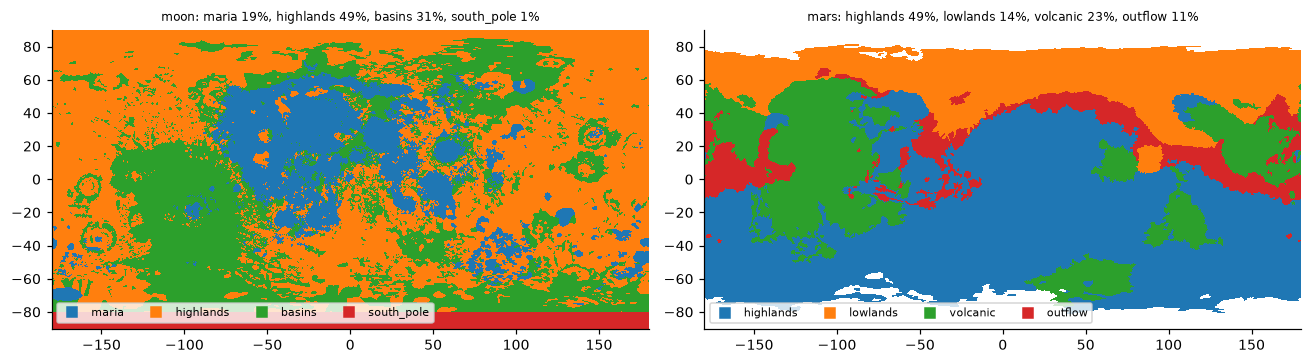

In [5]:
MAP_LAYER = {
    ("moon", "units"): "Unified_Geologic_Map_of_the_Moon_GIS/Lunar_GIS/Shapefiles/GeoUnits",
    ("moon", "lines"): "Unified_Geologic_Map_of_the_Moon_GIS/Lunar_GIS/Shapefiles/Linear_Features",
    ("mars", "units"): "SIM3292_MarsGlobalGeologicGIS_20M/SIM3292_Shapefiles/SIM3292_Global_Geology",
    ("mars", "lines"): "SIM3292_MarsGlobalGeologicGIS_20M/SIM3292_Shapefiles/SIM3292_Global_Structure",
}
REGIONS = {   # (key, title shown on the site). Region code = position + 1.
    "moon": [("maria", "Lunar maria"), ("highlands", "Lunar highlands"),
             ("basins", "Impact basin rings and ejecta"), ("south_pole", "South polar region")],
    "mars": [("highlands", "Southern cratered highlands"), ("lowlands", "Northern lowlands"),
             ("volcanic", "Volcanic provinces"), ("outflow", "Outflow channels and chaos")],
}
MARS_UNITS = {
    "highlands": "eNh mNh lNh Nhu HNhu eHh Nhe mNhm eNhm eHb HNb eAb lHb",
    "lowlands": "mAl lHl",
    "volcanic": "eHv lHv AHv lAv lNv Av lAvf lHvf Hve Nve Ave",
    "outflow": "Hto Ht lHt eHt HNt Htu AHtu",
    "_excluded": "Ap Apu lApc lApd Hp Hpe Hpu",          # polar units: no region
}
FILL, EXCLUDED = 0, 255
RES_DEG = 0.125
REGION_KEYS = [f"{w}:{k}" for w in WORLDS for k, _ in REGIONS[w]]
REGION_TITLE = [t for w in WORLDS for _, t in REGIONS[w]]


def parse_dbf(raw):
    # dBASE table -> list of dicts (all fields as stripped strings).
    n_rec, head_len, rec_len = struct.unpack("<IHH", raw[4:12])
    fields, o = [], 32
    while raw[o] != 0x0D:
        fields.append((raw[o:o + 11].split(b"\0")[0].decode(), raw[o + 16]))
        o += 32
    rows = []
    for i in range(n_rec):
        rec, pos, row = raw[head_len + i * rec_len: head_len + (i + 1) * rec_len], 1, {}
        for name, length in fields:
            row[name] = rec[pos:pos + length].decode("utf-8", "replace").strip()
            pos += length
        rows.append(row)
    return rows


def read_shp_parts(raw):
    # PolyLine / Polygon (also Z and M variants) -> per record, a list of (n, 2) x-y arrays.
    out, o = [], 100
    while o + 8 <= len(raw):
        clen = struct.unpack(">i", raw[o + 4:o + 8])[0] * 2
        c, o = raw[o + 8:o + 8 + clen], o + 8 + clen
        if struct.unpack("<i", c[:4])[0] == 0:
            out.append([])
            continue
        n_parts, n_pts = struct.unpack("<ii", c[36:44])
        starts = np.frombuffer(c, "<i4", n_parts, 44)
        pts = np.frombuffer(c, "<f8", 2 * n_pts, 44 + 4 * n_parts).reshape(-1, 2)
        out.append(np.split(pts, starts[1:]))
    return out


def wrap_lon(lon):
    return (np.asarray(lon) + 180.0) % 360.0 - 180.0


def map_layer(world, kind):
    # One layer of a geologic map as (attribute rows, parts in lon/lat degrees).
    stem = MAP_LAYER[(world, kind)]
    name, d = stem.rsplit("/", 1)[1], RAW / "geology"
    if not all((d / f"{name}{e}").exists() for e in (".shp", ".dbf", ".prj")):
        with zipfile.ZipFile(need(f"geology_{world}")) as zf:
            for ext in (".shp", ".dbf", ".prj"):
                (d / f"{name}{ext}").write_bytes(zf.read(stem + ext))
    attrs = parse_dbf((d / f"{name}.dbf").read_bytes())
    parts = read_shp_parts((d / f"{name}.shp").read_bytes())
    crs = CRS.from_wkt((d / f"{name}.prj").read_text())
    tr = Transformer.from_crs(crs, crs.geodetic_crs, always_xy=True) if crs.is_projected else None
    out = []
    for pp in parts:
        ll = []
        for p in pp:
            x, y = tr.transform(p[:, 0], p[:, 1]) if tr else (p[:, 0], p[:, 1])
            ll.append(np.column_stack([x, y]))
        out.append(ll)
    return attrs, out


def unit_code(world, a):
    # Region code of one map unit: 1..4, FILL (take the surroundings) or EXCLUDED.
    if world == "moon":
        d = a["FIRST_Un_2"].lower()
        if "basin" in d or "formation" in d:
            return 3
        if "mare" in d or "dark mantling" in d:
            return 1
        return FILL if "crater" in d else 2
    for i, (key, _) in enumerate(REGIONS["mars"]):
        if a["Unit"] in MARS_UNITS[key].split():
            return i + 1
    return EXCLUDED if a["Unit"] in MARS_UNITS["_excluded"].split() else FILL


def region_raster(world):
    path = RAW / "geology" / f"regions_{world}_v1.npz"
    if path.exists():
        with np.load(path) as f:
            return f["grid"]
    attrs, parts = map_layer(world, "units")
    shape = (int(180 / RES_DEG), int(360 / RES_DEG))
    T = Affine(RES_DEG, 0, -180, 0, -RES_DEG, 90)
    codes = np.array([unit_code(world, a) for a in attrs])
    grid = np.zeros(shape, np.uint8)
    for c in np.unique(codes):
        if c == FILL:
            continue
        # Every ring is burnt with +1; odd counts are inside (holes cancel), whatever the ring order.
        shapes = [({"type": "Polygon", "coordinates": [ring.tolist()]}, 1)
                  for i in np.flatnonzero(codes == c) for ring in parts[i] if len(ring) >= 4]
        cnt = rasterize(shapes, out_shape=shape, transform=T, merge_alg=MergeAlg.add, dtype="uint8")
        grid[(cnt % 2) == 1] = c
    known = grid != FILL
    idx = ndimage.distance_transform_edt(~known, return_distances=False, return_indices=True)
    grid = grid[tuple(idx)]                                # craters and gaps take the nearest region
    if world == "moon":
        lat = 90 - (np.arange(shape[0]) + 0.5) * RES_DEG
        grid[lat < -80.0, :] = 4
    np.savez_compressed(path, grid=grid)
    return grid


REGION_GRID = {w: region_raster(w) for w in WORLDS}


def region_code(world, lat, lon):
    g = REGION_GRID[world]
    i = np.clip(((90.0 - np.asarray(lat)) / RES_DEG).astype(int), 0, g.shape[0] - 1)
    j = np.clip(((wrap_lon(lon) + 180.0) / RES_DEG).astype(int), 0, g.shape[1] - 1)
    return g[i, j]


fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, w in zip(axes, WORLDS):
    g = REGION_GRID[w]
    area = np.cos(np.radians(90 - (np.arange(g.shape[0]) + 0.5) * RES_DEG))[:, None] * np.ones_like(g, float)
    share = {k: area[g == i + 1].sum() / area.sum() for i, (k, _) in enumerate(REGIONS[w])}
    im = ax.imshow(np.where(g == EXCLUDED, np.nan, g.astype(float)), cmap="tab10", vmin=0.5, vmax=10.5,
                   extent=(-180, 180, -90, 90), interpolation="nearest")
    ax.set_title(f"{w}: " + ", ".join(f"{k} {100 * v:.0f}%" for k, v in share.items()), fontsize=8)
    for i, (k, _) in enumerate(REGIONS[w]):
        ax.plot([], [], "s", color=plt.cm.tab10((i + 0.5) / 10), label=k)
    ax.legend(fontsize=7, loc="lower left", ncol=4)
plt.tight_layout(); plt.show()

In [6]:
def dbf_columns(fobj, cols, chunk=100_000):
    # Stream a few numeric columns out of a big .dbf (the Robbins Moon table is 577 MB unzipped).
    head = fobj.read(32)
    n_rec, head_len, rec_len = struct.unpack("<IHH", head[4:12])
    desc = fobj.read(head_len - 32)
    fields, o = [], 0
    while desc[o] != 0x0D:
        fields.append((desc[o:o + 11].split(b"\0")[0].decode(), desc[o + 16]))
        o += 32
    dt = np.dtype([("_del", "S1")] + [(n, f"S{l}") for n, l in fields])
    out, left = {c: [] for c in cols}, n_rec
    while left > 0:
        k = min(chunk, left)
        arr = np.frombuffer(fobj.read(k * rec_len), dtype=dt, count=k)
        for c in cols:
            out[c].append(pd.to_numeric(pd.Series(arr[c].astype(str)).str.strip(), errors="coerce").values)
        left -= k
    return {c: np.concatenate(v) for c, v in out.items()}


def gazetteer(world):
    with zipfile.ZipFile(need(f"gazetteer_{world}")) as zf:
        df = pd.DataFrame(parse_dbf(zf.read(next(n for n in zf.namelist() if n.lower().endswith(".dbf")))))
    for c in ("diameter", "center_lon", "center_lat", "min_lon", "max_lon", "min_lat", "max_lat"):
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df[df.approval.str.startswith("Adopted")].copy()
    df["lon"], df["lat"] = wrap_lon(df.center_lon), df.center_lat
    df["kind"] = df["type"].str.split(",").str[0].str.strip()
    return df.dropna(subset=["lat", "lon"]).reset_index(drop=True)


def robbins(world):
    # Centre and rim diameter of every crater of 1 km and larger. Cut to a small npz on first use.
    small = RAW / "robbins" / f"robbins_{world}.npz"
    if not small.exists():
        with zipfile.ZipFile(need(f"robbins_{world}")) as zf:
            if world == "moon":
                with zf.open(next(n for n in zf.namelist() if n.endswith(".dbf"))) as f:
                    c = dbf_columns(f, ["LAT_EL_IM", "LON_EL_IM", "DIAM_C_IM"])
                lat, lon, d = c["LAT_EL_IM"], c["LON_EL_IM"], c["DIAM_C_IM"]
            else:
                with zf.open(next(n for n in zf.namelist() if n.endswith(".csv"))) as f:
                    c = pd.read_csv(f, usecols=["LAT_CIRC_IMG", "LON_CIRC_IMG", "DIAM_CIRC_IMG"], encoding="utf-8-sig")
                lat, lon, d = c.LAT_CIRC_IMG.values, c.LON_CIRC_IMG.values, c.DIAM_CIRC_IMG.values
        np.savez_compressed(small, lat=lat.astype(np.float32), lon=wrap_lon(lon).astype(np.float32), diameter=d.astype(np.float32))
    with np.load(small) as f:
        return pd.DataFrame({k: f[k].astype(float) for k in f.files}).dropna()


def line_features(world):
    attrs, parts = map_layer(world, "lines")
    return [dict(attrs=a, parts=[np.column_stack([wrap_lon(p[:, 0]), p[:, 1]]) for p in pp], id=f"{world}-line-{i}")
            for i, (a, pp) in enumerate(zip(attrs, parts)) if pp]


def haversine_m(lat1, lon1, lat2, lon2, R):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2) - np.radians(lon1)
    return 2 * R * np.arcsin(np.sqrt(np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2))


def points_along(parts, step_m, R):
    # Points every step_m along a polyline (first one half a step in), as (lat, lon).
    out = []
    for p in parts:
        if len(p) < 2:
            continue
        lon, lat = p[:, 0], p[:, 1]
        seg = haversine_m(lat[:-1], lon[:-1], lat[1:], lon[1:], R)
        seg[np.abs(np.diff(lon)) > 180] = 0.0            # never interpolate across the date line
        cum = np.r_[0.0, np.cumsum(seg)]
        for s in np.arange(step_m / 2, cum[-1], step_m):
            j = min(int(np.searchsorted(cum, s, side="right")) - 1, len(seg) - 1)
            t = (s - cum[j]) / seg[j] if seg[j] > 0 else 0.0
            out.append((lat[j] + t * (lat[j + 1] - lat[j]), lon[j] + t * (lon[j + 1] - lon[j])))
    return out


def destination(lat, lon, dist_m, az, R):
    # Point dist_m from (lat, lon) along azimuth az (radians), on a sphere of radius R.
    p1, l1, d = math.radians(lat), math.radians(lon), dist_m / R
    p2 = math.asin(math.sin(p1) * math.cos(d) + math.cos(p1) * math.sin(d) * math.cos(az))
    l2 = l1 + math.atan2(math.sin(az) * math.sin(d) * math.cos(p1), math.cos(d) - math.sin(p1) * math.sin(p2))
    return math.degrees(p2), (math.degrees(l2) + 180) % 360 - 180


def group_of(world, lat, lon):
    return f"{world}:{int(lat // 10)}:{int(lon // 10)}"


def attr_is(field, *values):
    return lambda a: a.get(field, "") in values


def attr_starts(field, prefix):
    return lambda a: a.get(field, "").lower().startswith(prefix) and "catena" not in a.get("COMMENT", "").lower()


def is_catena(a):
    return "catena" in a.get("COMMENT", "").lower()


ANY = (0.0, 1e9)
CRATER_TAGS = ("small_crater", "crater_rim", "crater_floor", "crater_chain")
TAGS = {   # (tag, source, selector, placement)
    "moon": [
        ("small_crater", "robbins", (1.2, 3.2), "centre"),
        ("crater_rim", "robbins", (8, 60), "rim"),
        ("crater_floor", "robbins", (60, 300), "floor"),
        ("crater_chain", "line", is_catena, "along"),
        ("sinuous_rille", "line", attr_starts("TYPE", "channel"), "along"),
        ("graben", "line", attr_starts("TYPE", "graben"), "along"),
        ("wrinkle_ridge", "line", attr_starts("TYPE", "ridge crest"), "along"),
        ("massif", "gaz", ({"Mons", "Promontorium"}, ANY), "box"),
    ],
    "mars": [
        ("small_crater", "robbins", (1.0, 3.2), "centre"),
        ("crater_rim", "robbins", (8, 60), "rim"),
        ("crater_floor", "robbins", (60, 300), "floor"),
        ("volcanic_edifice", "gaz", ({"Mons", "Tholus", "Patera"}, ANY), "box"),
        ("lava_flow", "line", attr_is("Interpreta", "Lobate flow"), "along"),
        ("wrinkle_ridge", "line", attr_is("Interpreta", "Wrinkle ridge"), "along"),
        ("graben", "line", attr_is("Interpreta", "Graben axis"), "along"),
        ("scarp", "line", attr_is("Interpreta", "Scarp"), "along"),
        ("channel", "line", attr_is("Interpreta", "Channel axis", "Outflow Channel"), "along"),
        ("yardang", "line", attr_is("Interpreta", "Yardangs"), "along"),
        ("mesa", "gaz", ({"Mensa", "Collis"}, ANY), "box"),
        ("chaos", "gaz", ({"Chaos", "Labyrinthus"}, ANY), "box"),
        ("canyon", "gaz", ({"Chasma"}, ANY), "box"),
    ],
}


def tag_candidates(world, tdef, rng, gaz, lines):
    tag, src, sel, how = tdef
    R, cap, out = rt.RADIUS_M[world], CFG["max_per_feature"], []
    if src == "robbins":
        df = robbins(world)
        df = df[df.diameter.between(*sel)]
        for i, r in df.sample(n=min(len(df), 30 * CFG["per_region"]), random_state=int(rng.integers(1 << 31))).iterrows():
            rad_m, az = 500.0 * r.diameter, rng.uniform(0, 2 * np.pi)
            dist = {"centre": 0.0, "rim": rad_m, "floor": rng.uniform(0.2, 0.45) * rad_m}[how]
            lat, lon = destination(r.lat, r.lon, dist, az, R) if dist else (r.lat, r.lon)
            label = {"centre": f"{r.diameter:.1f} km crater", "rim": f"rim of a {r.diameter:.0f} km crater",
                     "floor": f"floor of a {r.diameter:.0f} km crater"}[how]
            out.append((f"{world}-robbins-{i}", r.lat, r.lon, lat, lon, label))
    elif src == "gaz":
        kinds, (dmin, dmax) = sel
        for _, r in gaz[gaz.kind.isin(kinds) & gaz.diameter.between(dmin, dmax)].iterrows():
            for _ in range(cap):
                dlat, dlon = (r.max_lat - r.min_lat) / 2, ((r.max_lon - r.min_lon) % 360.0) / 2
                if not (np.isfinite(dlat) and np.isfinite(dlon)) or dlon > 90 or dlat <= 0:
                    dlat = dlon = math.degrees(500.0 * r.diameter / R)
                lat = float(np.clip(r.lat + rng.uniform(-0.5, 0.5) * dlat, -89.9, 89.9))
                lon = float(wrap_lon(r.lon + rng.uniform(-0.5, 0.5) * dlon))
                out.append((f"{world}-gaz-{r['name']}", r.lat, r.lon, lat, lon, f"{tag.replace('_', ' ')} ({r['name']})"))
    else:
        for f in lines:
            if not sel(f["attrs"]):
                continue
            pts = points_along(f["parts"], CFG["line_step_km"] * 1000.0, R)
            if not pts:
                continue
            ref = pts[len(pts) // 2]
            for j in rng.choice(len(pts), size=min(cap, len(pts)), replace=False):
                out.append((f["id"], ref[0], ref[1], pts[j][0], pts[j][1], tag.replace("_", " ")))
    return out


GAZ = {w: gazetteer(w) for w in WORLDS}
for w in WORLDS:
    print(f"{w}: {len(GAZ[w])} named features, {len(robbins(w))} Robbins craters, {len(line_features(w))} mapped lines")

moon: 9087 named features, 1296758 Robbins craters, 3800 mapped lines
mars: 2055 named features, 385049 Robbins craters, 3593 mapped lines


In [7]:
STAC = "https://stac.astrogeology.usgs.gov/api/search"
KAGUYA = ["kaguya_terrain_camera_usgs_dtms_v2_equi", "kaguya_terrain_camera_usgs_dtms_v2_southpolar",
          "kaguya_terrain_camera_usgs_dtms_v2_northpolar"]


def dtm_href(item):
    a = item["assets"]
    return next(a[k]["href"] for k in ("dtm", "dem", "geoid_adjusted_dem") if k in a)


def kaguya_hrefs(lat, lon, limit=4):
    for coll in KAGUYA:
        body = json.dumps({"collections": [coll], "limit": limit,
                           "intersects": {"type": "Point", "coordinates": [lon, lat]}}).encode()
        items = json.loads(rd.http(STAC, body))["features"]
        if items:
            return [dtm_href(i) for i in items]
    return []


def ctx_footprints():
    # real CTX DTM outlines (not bounding boxes), one ring per polygon part
    with np.load(need("ctx_footprints")) as f:
        href, item, start, xy = f["href"], f["ring_item"], f["ring_start"], f["xy"].astype(np.float64)
    rings, keep = [], []
    for r in range(len(item)):
        ring = xy[start[r]:start[r + 1]].copy()
        ring[:, 0] = np.where(ring[:, 0] > 180, ring[:, 0] - 360, ring[:, 0])
        if len(ring) < 4 or np.ptp(ring[:, 0]) > 180:             # degenerate or wraps the date line
            continue
        rings.append(ring); keep.append(item[r])
    return href, np.array(keep), rings


CTX_HREF, CTX_ITEM, CTX_RINGS = ctx_footprints()
CTX_BOX = np.array([[r[:, 0].min(), r[:, 1].min(), r[:, 0].max(), r[:, 1].max()] for r in CTX_RINGS])
CTX_PATH = [PolyPath(r) for r in CTX_RINGS]
COV_DEG = 0.05
CTX_COVER = rasterize(((dict(type="Polygon", coordinates=[r.tolist()]), 1) for r in CTX_RINGS),
                      out_shape=(int(180 / COV_DEG), int(360 / COV_DEG)), transform=Affine(COV_DEG, 0, -180, 0, -COV_DEG, 90),
                      fill=0, dtype="uint8").astype(bool)
_w = np.cos(np.radians(90 - (np.arange(CTX_COVER.shape[0]) + 0.5) * COV_DEG))[:, None]
print(f"CTX DTMs: {len(CTX_HREF)} with {len(CTX_RINGS)} footprint rings; footprints cover {100 * (CTX_COVER * _w).sum() / (_w.sum() * CTX_COVER.shape[1]):.1f}% of Mars")


def ctx_covered(lat, lon):
    i = np.clip(((90.0 - np.asarray(lat)) / COV_DEG).astype(int), 0, CTX_COVER.shape[0] - 1)
    j = np.clip(((wrap_lon(lon) + 180.0) / COV_DEG).astype(int), 0, CTX_COVER.shape[1] - 1)
    return CTX_COVER[i, j]


def ctx_hrefs(lat, lon, limit=4):
    # DTMs whose real footprint holds the point and a ring of points ctx_inset_km around it, deepest first
    R, d = rt.RADIUS_M["mars"], CFG["ctx_inset_km"] * 1000.0
    ring = np.array([destination(lat, lon, f * d, az, R)[::-1] for f in (0.5, 1.0) for az in np.linspace(0, 2 * np.pi, 8, endpoint=False)])
    cand = np.flatnonzero((CTX_BOX[:, 0] <= lon) & (lon <= CTX_BOX[:, 2]) & (CTX_BOX[:, 1] <= lat) & (lat <= CTX_BOX[:, 3]))
    scored = []
    for r in cand:
        p = CTX_PATH[r]
        if p.contains_point((lon, lat)):
            scored.append((p.contains_points(ring).mean(), r))
    out = []
    for share, r in sorted(scored, reverse=True):
        h = str(CTX_HREF[CTX_ITEM[r]])
        if share == 1.0 and h not in out:
            out.append(h)
    return out[:limit]


def site_hrefs(world, lat, lon):
    if world == "moon":
        return ([POLAR_LOCAL["site"]] if lat <= CFG["polar_lat"] else []) + kaguya_hrefs(lat, lon)
    return ctx_hrefs(lat, lon)


def lat_ok(world, lat):
    lim = np.where((world == "moon") & (np.asarray(lat) <= CFG["polar_lat"]), CFG["polar_max_lat"], CFG["max_lat"])
    return np.abs(lat) <= lim


def sample_background(world, code, n, rng):
    out = []
    for _ in range(400):
        m = 20000
        lon = rng.uniform(-180, 180, m)
        if world == "moon" and code == 4:        # the polar cap is small: sample it directly
            lat = np.degrees(np.arcsin(rng.uniform(np.sin(np.radians(-CFG["polar_max_lat"])), np.sin(np.radians(CFG["polar_lat"])), m)))
        else:
            lat = np.degrees(np.arcsin(rng.uniform(-1, 1, m)))
        ok = (region_code(world, lat, lon) == code) & lat_ok(world, lat)
        if world == "mars":
            ok &= ctx_covered(lat, lon)
        out += list(zip(lat[ok].tolist(), lon[ok].tolist()))
        if len(out) >= n:
            break
    return out[:n]


def nearest_name(world, lat, lon):
    g = GAZ[world]
    d = haversine_m(lat, lon, g.lat.values, g.lon.values, rt.RADIUS_M[world])
    j = int(np.argmin(d))
    return g["name"].iloc[j], d[j] / 1000.0


def library_locations(world, rng):
    # Candidate locations per region (shuffled): half background, half on tagged landforms.
    lines = line_features(world)
    rows = [(t[0], *c) for t in TAGS[world] for c in tag_candidates(world, t, rng, GAZ[world], lines)]
    pool = pd.DataFrame(rows, columns=["tag", "feature", "rlat", "rlon", "lat", "lon", "label"])
    pool = pool[lat_ok(world, pool.lat.values)]
    if world == "mars":
        pool = pool[ctx_covered(pool.lat.values, pool.lon.values)]
    pool = pool.assign(code=region_code(world, pool.lat.values, pool.lon.values))
    out = {}
    for i, (key, title) in enumerate(REGIONS[world]):
        n_target = int(CFG["per_region"] * CFG["oversample"][world])
        sub, locs = pool[pool.code == i + 1], []
        tags = sorted(sub.tag.unique())
        for t in tags:
            st = sub[sub.tag == t]
            cnt = st.groupby("feature").feature.transform("count").values
            k = min(len(st), int(math.ceil(n_target * CFG["tag_share"] / len(tags))))
            for j in rng.choice(len(st), size=k, replace=False, p=(1 / cnt) / (1 / cnt).sum()):
                r = st.iloc[j]
                locs.append(dict(world=world, region=key, tag=t, label=r.label, lat=float(r.lat), lon=float(r.lon),
                                 feature=r.feature, group=group_of(world, r.rlat, r.rlon)))
        for k, (lat, lon) in enumerate(sample_background(world, i + 1, n_target - len(locs), rng)):
            locs.append(dict(world=world, region=key, tag="background", label=title.lower(), lat=lat, lon=lon,
                             feature=f"{world}-{key}-bg-{k}", group=group_of(world, lat, lon)))
        out[key] = [locs[j] for j in rng.permutation(len(locs))]
    return out


READ_STATS = {"site_missing": 0, "striped": 0, "regional_missing": 0, "polar_site": 0}


def read_location(p):
    # One library location at both scales -> tokens, block features and small DEMs. None if unusable.
    world, lat, lon, R = p["world"], p["lat"], p["lon"], rt.RADIUS_M[p["world"]]
    site = None
    for href in site_hrefs(world, lat, lon):
        polar = href == POLAR_LOCAL["site"]
        try:
            dem, native = rd.read_raster_window(href, lat, lon, R, rt.SCALES["site"]["res"], max_nodata=CFG["site_max_nodata"])
        except Exception:
            continue
        stripe = rt.stripe_score(dem[rt.PAD_PX:-rt.PAD_PX, rt.PAD_PX:-rt.PAD_PX])
        if world == "moon" and not polar and stripe > CFG["stripe_max"]:     # stripes are a Kaguya problem, not LOLA
            READ_STATS["striped"] += 1
            continue
        if polar:
            READ_STATS["polar_site"] += 1
            href = rd.POLAR_DEM["site"]                     # store the public URL, so the server can draw it
        site = (dem, native, href, stripe)
        break
    if site is None:
        READ_STATS["site_missing"] += 1
        return None
    reg = None
    for src_ in ([POLAR_LOCAL["regional"]] if world == "moon" and lat <= CFG["polar_lat"] else []) + [rd.GLOBAL_DEM[world]]:
        try:
            reg, _ = rd.read_raster_window(src_, lat, lon, R, rt.SCALES["regional"]["res"], max_nodata=0.05)
            break
        except Exception:
            continue
    if reg is None:
        READ_STATS["regional_missing"] += 1
        return None
    dem, native, href, stripe = site
    ts, bs = rt.compute_features(dem, R, "site")
    tr_, br = rt.compute_features(reg, R, "regional")
    c = slice(rt.PAD_PX, -rt.PAD_PX)
    near, dkm = nearest_name(world, lat, lon)
    return dict(tokens_site=ts.astype(np.float32), block_site=bs, tokens_regional=tr_.astype(np.float32), block_regional=br,
                dem_site=dem[c, c].astype(np.float32), dem_regional=reg[c, c].astype(np.float32),
                href=href, native_m=native, stripe=stripe, name=f"{p['label']}, {dkm:.0f} km from {near}")


LIB_FIELDS = ("world", "region", "tag", "name", "lat", "lon", "feature", "group", "href")


def build_library(world, rng):
    path = CACHE / f"library_{world}_{PROFILE}_{CACHE_TAG}.npz"
    if path.exists():
        with np.load(path, allow_pickle=False) as f:
            return {k: f[k] for k in f.files}
    locs = library_locations(world, rng)
    kept, cursor = {k: [] for k in locs}, {k: 0 for k in locs}
    for rnd in range(12):
        jobs = []
        for k in locs:
            need = CFG["per_region"] - len(kept[k])
            take = locs[k][cursor[k]:cursor[k] + int(need * (2.2 if world == "moon" else 1.4)) + 4] if need > 0 else []
            cursor[k] += len(take)
            jobs += take
        if not jobs:
            break
        res = run_parallel(read_location, jobs, f"{world} round {rnd + 1}")
        for p, x in zip(jobs, res):
            if x is not None and len(kept[p["region"]]) < CFG["per_region"]:
                kept[p["region"]].append(p | x)
    rows = [r for k in kept for r in kept[k]]
    lib = dict(
        **{f: np.stack([r[f] for r in rows]) for f in ("tokens_site", "block_site", "tokens_regional", "block_regional",
                                                      "dem_site", "dem_regional")},
        native_m=np.array([r["native_m"] for r in rows]), stripe=np.array([r["stripe"] for r in rows]),
        **{c: np.array([r[c] for r in rows]) for c in LIB_FIELDS})
    np.savez_compressed(path, **lib)
    return lib


libs = {w: build_library(w, np.random.default_rng(SEED + i)) for i, w in enumerate(WORLDS)}
print("reads skipped this run:", READ_STATS)
for w, L in libs.items():
    print(f"{w}: {len(L['region'])} blocks from {len(np.unique(L['feature']))} features")
pd.concat({w: pd.crosstab(pd.Series(L["region"], name="region"), pd.Series(L["tag"], name="tag")) for w, L in libs.items()}).fillna(0).astype(int)

CTX DTMs: 44628 with 44646 footprint rings; footprints cover 11.7% of Mars


reads skipped this run: {'site_missing': 0, 'striped': 0, 'regional_missing': 0, 'polar_site': 0}
moon: 2236 blocks from 2078 features
mars: 2400 blocks from 2141 features


tag              background  crater_chain  crater_floor  crater_rim  graben  \
     region                                                                   
moon basins             295            22            54          27      38   
     highlands          234            22            41          20      39   
     maria              365            26            33          11      24   
     south_pole         491             0             3          35       0   
mars highlands          340             0            35          28      23   
     lowlands           514             0             2          34       3   
     outflow            319             0            12          28      28   
     volcanic           334             0            13          26      24   

tag              massif  sinuous_rille  small_crater  wrinkle_ridge  canyon  \
     region                                                                   
moon basins          18             14            23              5       0   
     highlands       44             31            31             78       0   
     maria           32             43            15             51       0   
     south_pole      16              0            55              0       0   
mars highlands        0              0            22             28       9   
     lowlands         0              0            23              6       0   
     outflow          0              0            20             27      21   
     volcanic         0              0            20             30      28   

tag              channel  chaos  lava_flow  mesa  scarp  volcanic_edifice  \
     region                                                                 
moon basins            0      0          0     0      0                 0   
     highlands         0      0          0     0      0                 0   
     maria             0      0          0     0      0                 0   
     south_pole        0      0          0     0      0                 0   
mars highlands        22      3          0    31     20                39   
     lowlands          4      1          4     2      0                 7   
     outflow          20     29          0    30     16                22   
     volcanic         27      2         21    14     26                35   

tag              yardang  
     region               
moon basins            0  
     highlands         0  
     maria             0  
     south_pole        0  
mars highlands         0  
     lowlands          0  
     outflow          28  
     volcanic          0

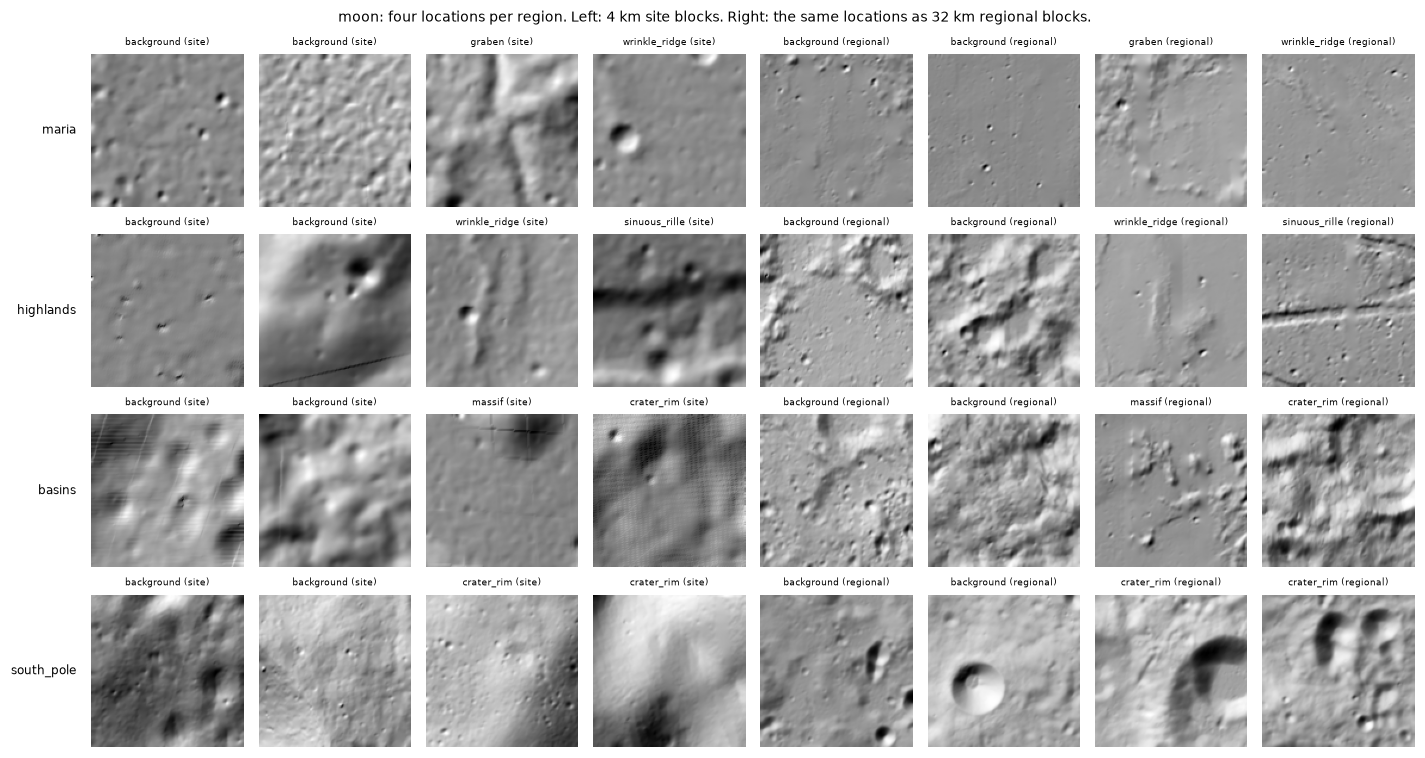

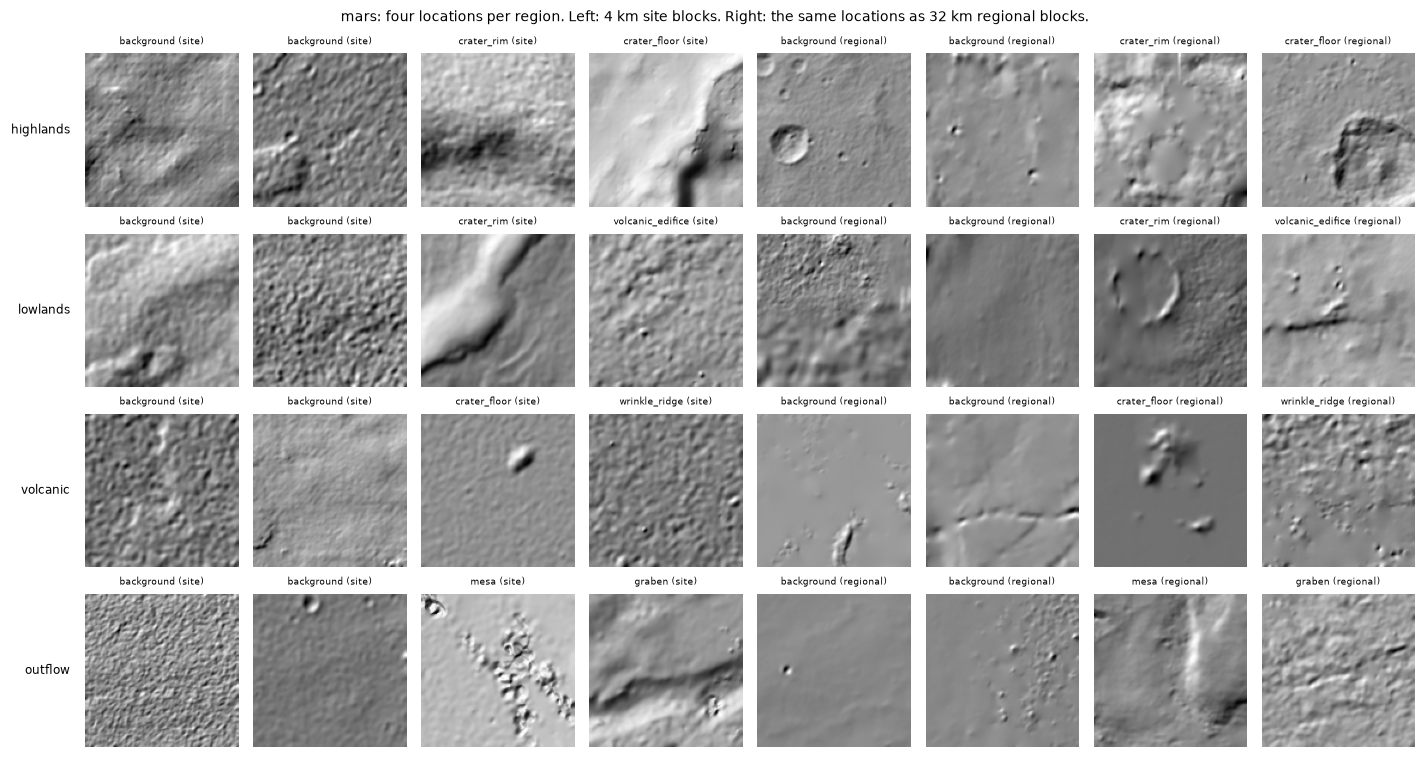

In [8]:
for w in WORLDS:
    L = libs[w]
    fig, axes = plt.subplots(len(REGIONS[w]), 8, figsize=(13, 1.75 * len(REGIONS[w])))
    for r_, (key, title) in enumerate(REGIONS[w]):
        ids = np.r_[np.flatnonzero((L["region"] == key) & (L["tag"] == "background"))[:2],
                    np.flatnonzero((L["region"] == key) & (L["tag"] != "background"))[:2]]
        for k, ax in enumerate(axes[r_]):
            ax.axis("off")
            if k % 4 < len(ids):
                i, s = ids[k % 4], ("site", "regional")[k // 4]
                ax.imshow(hillshade(L[f"dem_{s}"][i].astype(float), rt.SCALES[s]["res"]), cmap="gray")
                ax.set_title(f"{L['tag'][i]} ({s})", fontsize=6)
        axes[r_, 0].text(-0.1, 0.5, key, transform=axes[r_, 0].transAxes, ha="right", va="center", fontsize=8)
    plt.suptitle(f"{w}: four locations per region. Left: 4 km site blocks. Right: the same locations as 32 km regional blocks.", fontsize=9)
    plt.tight_layout(); plt.show()

In [9]:
def precip_grid():
    out = RAW / "climate" / "precip_10m_annual.npy"
    if not out.exists():
        z = need("worldclim")
        out.parent.mkdir(parents=True, exist_ok=True)
        total, bad = None, None
        for m in range(1, 13):
            with rasterio.open(f"zip://{z}!wc2.1_10m_prec_{m:02d}.tif") as ds:
                a = ds.read(1).astype(np.float64)
                miss = (a == ds.nodata) | (a < 0) if ds.nodata is not None else (a < 0)
            total = a if total is None else total + a
            bad = miss if bad is None else bad | miss
        np.save(out, np.where(bad, 65535, np.clip(total, 0, 65534)).astype(np.uint16))
    return np.load(out)


PRECIP = precip_grid()


class _PrecipOnly:                      # lets rt.precip_at run before the model object exists
    precip = PRECIP


def merged_sites():
    # ml/analog_sites.csv: every site is named by an agency or programme document, or by 3+ peer-reviewed papers,
    # and its coordinates come from a gazetteer or the source itself. sites within 10 km of each other become one
    keep, Re = [], rt.RADIUS_M["earth"]
    for s in pd.read_csv(need("analog_sites"))[["name", "lat", "lon", "world"]].itertuples(index=False, name=None):
        if all(haversine_m(s[1], s[2], k[1], k[2], Re) > 10e3 for k in keep):
            keep.append(s)
    return keep


def check_site(site):
    # a field site should be mostly bare and dry. if the block is mostly tree/crop/built/water, look within snap_km
    # for the cleanest 4 km block; if nothing nearby is clean, drop the site (it's not a terrain or conditions analog)
    name, lat, lon, w = site
    cover = lambda la, lo: sum(np.nan_to_num(v) for k, v in rd.worldcover_shares(la, lo).items() if k in ("tree", "crop", "built", "water"))
    c0 = cover(lat, lon)
    if c0 <= CFG["cover_max"]:
        return dict(name=name, lat=lat, lon=lon, world=w, status="ok", moved_km=0.0, cover=c0)
    Re, best = rt.RADIUS_M["earth"], (c0, 0.0, lat, lon)
    for d in np.arange(2.0, CFG["snap_km"] + 0.1, 2.0):
        for az in np.linspace(0, 2 * np.pi, 8, endpoint=False):
            la, lo = destination(lat, lon, d * 1000, az, Re)
            c = cover(la, lo)
            if c < best[0] - 1e-6:
                best = (c, d, la, lo)
        if best[0] <= CFG["cover_max"]:
            break
    status = "moved" if best[0] <= CFG["cover_max"] else "dropped"
    return dict(name=name, lat=best[2], lon=best[3], world=w, status=status, moved_km=best[1], cover=best[0])


def checked_sites():
    path = CACHE / f"analog_sites_{CACHE_TAG}.json"
    if path.exists():
        return pd.DataFrame(json.loads(path.read_text()))
    sites = merged_sites()
    res = run_parallel(check_site, sites, "analog sites", every=50)
    df = pd.DataFrame([r if r else dict(name=s[0], lat=s[1], lon=s[2], world=s[3], status="ok", moved_km=0.0, cover=np.nan)
                       for s, r in zip(sites, res)])
    path.write_text(df.to_json(orient="records"))
    return df


FEATURED = [  # name, lat, lon, expected rank (1 = worst), written before scoring
    ("Dutch farmland", 52.52, 5.60, 1), ("Amazon rainforest", -3.40, -62.00, 1), ("Himalayan ridge", 27.95, 86.95, 2),
    ("Utah near MDRS", 38.40, -110.80, 3), ("Holuhraun lava field", 64.87, -16.83, 4),
    ("Lanzarote Timanfaya", 29.00, -13.75, 5), ("Meteor Crater", 35.027, -111.022, 5),
    ("Haughton crater", 75.38, -89.67, 6), ("McMurdo Dry Valleys", -77.52, 161.80, 6),
]
# name, lat, lon, rim diameter (km): locations from the USGS impact-site list, diameters from Wikidata (ml/earth_craters.csv).
# buried or eroded ones are dropped later by the relief filter
EARTH_CRATERS = list(pd.read_csv(need("earth_craters"))[["name", "lat", "lon", "diameter_km"]].itertuples(index=False, name=None))


def gvp_volcanoes(n, rng):
    path = need("gvp")
    fs = json.loads(path.read_text())["features"]
    keep = [f for f in fs if str(f["properties"].get("Primary_Volcano_Type", "")).startswith(("Shield", "Caldera", "Volcanic field", "Pyroclastic cone"))]
    pick = rng.choice(len(keep), size=min(n, len(keep)), replace=False)
    return [(keep[i]["properties"]["Volcano_Name"], keep[i]["geometry"]["coordinates"][1],
             keep[i]["geometry"]["coordinates"][0]) for i in pick]


def random_land(n, rng):
    tiles, out = rd.glo30_tiles(), []
    while len(out) < n:
        lat, lon = float(np.degrees(np.arcsin(rng.uniform(-1, 1)))), float(rng.uniform(-180, 180))
        if rd.glo30_tile_name(int(np.floor(lat)), int(np.floor(lon))) in tiles:
            out.append((lat, lon))
    return out


def earth_jobs(rng):
    J = lambda name, lat, lon, set_, **k: dict(name=name, lat=float(lat), lon=float(lon), set=set_,
                                               target=k.get("target", ""), expected=k.get("expected", 0),
                                               tag=k.get("tag", ""), split=k.get("split", ""))
    jobs = [J(f"random {la:.2f},{lo:.2f}", la, lo, "random") for la, lo in random_land(int(CFG["n_random_land"] * 1.3), rng)]
    Re = rt.RADIUS_M["earth"]
    far = lambda la, lo: all(haversine_m(la, lo, f[1], f[2], Re) > 50e3 for f in FEATURED)
    sites = checked_sites()
    print("analog sites:", sites["status"].value_counts().to_dict())
    sites = sites[sites["status"] != "dropped"]
    jobs += [J(r.name, r.lat, r.lon, "analog", target=r.world) for r in sites.itertuples() if far(r.lat, r.lon)]
    jobs += [J(n, la, lo, "featured", expected=e) for n, la, lo, e in FEATURED]
    for k, (n, la, lo, d) in enumerate([c for c in EARTH_CRATERS if c[3] >= CFG["min_crater_km"]]):
        split = "train" if CFG["cross_weight"] > 0 and k % 2 == 0 else "test"      # nothing trains on them when the weight is 0
        if d <= 4.5:
            jobs.append(J(n, la, lo, "crater", tag="small_crater", split=split))
        else:                                               # three rim blocks, 120 degrees apart
            for az in (0.0, 2.094, 4.189):
                la2, lo2 = destination(la, lo, 500.0 * d, az, Re)
                jobs.append(J(f"{n} rim", la2, lo2, "crater", tag="crater_rim", split=split))
    jobs += [J(n, la, lo, "volcano", tag="volcano", split="train" if CFG["cross_weight"] > 0 and k % 2 == 0 else "test")
             for k, (n, la, lo) in enumerate(gvp_volcanoes(CFG["n_volcanoes"], rng))]
    return jobs


def earth_block(job):
    lat, lon, R = job["lat"], job["lon"], rt.RADIUS_M["earth"]
    site = rd.read_glo30_window(lat, lon, rt.SCALES["site"]["res"])
    if np.isnan(site).mean() > 0.5 or rd.flat_fraction(np.nan_to_num(site, nan=-1e9)) > 0.5:
        return None
    reg = rd.read_glo30_window(lat, lon, rt.SCALES["regional"]["res"])
    if np.isnan(reg).mean() > 0.6:
        return None                                         # a small island: no regional context
    ts, bs = rt.compute_features(site, R, "site")
    tr_, br = rt.compute_features(reg, R, "regional")
    env = rd.worldcover_shares(lat, lon)
    env["precip"] = rt.precip_at(_PrecipOnly, lat, lon)
    return dict(tokens_site=ts.astype(np.float32), block_site=bs, tokens_regional=tr_.astype(np.float32), block_regional=br,
                dem_site=site.astype(np.float32), dem_regional=reg.astype(np.float32), **env)


def build_earth(rng):
    # per-block cache: a block that was already read (same set, name and coordinates) is reused, so changing a
    # site list only reads the new blocks. reads that failed (ocean, lakes) are remembered too
    path = CACHE / f"earth_{PROFILE}_{CACHE_TAG}.npz"
    key = lambda s_, n, la, lo: f"{s_}|{n}|{float(la):.5f}|{float(lo):.5f}"
    old, have, failed, dem_row = None, {}, set(), {}
    if path.exists():
        with np.load(path, allow_pickle=False) as f:
            old = {k: f[k] for k in f.files}
        have = {key(*t): i for i, t in enumerate(zip(old["set"], old["name"], old["lat"], old["lon"]))}
        failed = set(old["failed"].tolist()) if "failed" in old else set()
        dem_row = {int(i): k for k, i in enumerate(old["dem_index"])}
    jobs = earth_jobs(rng)
    keys = [key(j["set"], j["name"], j["lat"], j["lon"]) for j in jobs]
    todo = [i for i, k in enumerate(keys) if k not in have and k not in failed]
    print(f"earth blocks: {len(jobs)} wanted, {len(jobs) - len(todo)} already cached or known to fail, {len(todo)} to read")
    res = dict(zip(todo, run_parallel(earth_block, [jobs[i] for i in todo], "earth"))) if todo else {}
    failed |= {keys[i] for i, r in res.items() if r is None}
    fields = ("tokens_site", "block_site", "tokens_regional", "block_regional")
    kept = []
    for i, (j, k) in enumerate(zip(jobs, keys)):
        if k in have:
            o = have[k]
            r = {f: old[f][o] for f in fields} | {g: float(old[g][o]) for g in rt.ENV_NAMES}
            if o in dem_row:
                r |= dict(dem_site=old["dem_site"][dem_row[o]], dem_regional=old["dem_regional"][dem_row[o]])
        else:
            r = res.get(i)
        if r is None or (j["set"] == "crater" and r["block_site"][0] < CFG["crater_min_relief"]):   # buried or eroded
            continue
        kept.append((j, r))
    rand = [k for k in kept if k[0]["set"] == "random"][:CFG["n_random_land"]]
    kept = rand + [k for k in kept if k[0]["set"] != "random"]
    keep_dem = np.array([j["set"] in ("featured", "analog", "crater") and "dem_site" in r for j, r in kept])
    E = dict(
        **{c: np.array([j[c] for j, _ in kept]) for c in ("name", "lat", "lon", "set", "target", "expected", "tag", "split")},
        **{f: np.stack([r[f] for _, r in kept]) for f in fields},
        dem_site=np.stack([r["dem_site"] for (j, r), k in zip(kept, keep_dem) if k]).astype(np.float32),
        dem_regional=np.stack([r["dem_regional"] for (j, r), k in zip(kept, keep_dem) if k]).astype(np.float32),
        dem_index=np.flatnonzero(keep_dem),
        **{g: np.array([r[g] for _, r in kept], dtype=float) for g in rt.ENV_NAMES},
        failed=np.array(sorted(failed) or [""]))
    np.savez_compressed(path, **E)
    return E


earth = build_earth(np.random.default_rng(SEED + 7))
earth_group = np.array([f"{int(a // 5)}:{int(b // 5)}" for a, b in zip(earth["lat"], earth["lon"])])
print(pd.Series(earth["set"]).value_counts().to_dict())
pd.DataFrame({g: earth[g] for g in rt.ENV_NAMES}).groupby(earth["set"]).mean().round(2)

  [analog sites] 50/96 done, 50 ok, 3s


  [analog sites] 96/96 done, 96 ok, 6s
analog sites: {'ok': 70, 'dropped': 15, 'moved': 11}
earth blocks: 3725 wanted, 2759 already cached or known to fail, 966 to read


  [earth] 200/966 done, 0 ok, 5s


  [earth] 400/966 done, 0 ok, 10s


  [earth] 600/966 done, 0 ok, 14s


  [earth] 800/966 done, 129 ok, 33s


  [earth] 966/966 done, 236 ok, 51s


{'random': 2500, 'volcano': 250, 'crater': 74, 'analog': 69, 'featured': 9}


,tree,crop,built,water,snow,bare,precip
analog,0.03,0.00,0.00,0.01,0.01,0.58,437.58
crater,0.26,0.11,0.01,0.07,0.00,0.21,549.15
featured,0.13,0.10,0.00,0.00,0.12,0.54,642.56
random,0.33,0.10,0.01,0.04,0.02,0.16,743.52
volcano,0.33,0.04,0.01,0.05,0.04,0.19,1091.57


In [10]:
lib = {k: np.concatenate([libs[w][k] for w in WORLDS]) for k in libs["moon"]}
N_LIB = len(lib["region"])
lib_region = np.array([REGION_KEYS.index(f"{w}:{r}") for w, r in zip(lib["world"], lib["region"])])
lib_group, lib_tag = lib["group"], lib["tag"]
world_idx = {w: np.flatnonzero(lib["world"] == w) for w in WORLDS}
members = [np.flatnonzero(lib_region == r) for r in range(len(REGION_KEYS))]
rand = earth["set"] == "random"

SC = {}
for s in SCALES:
    lt, et = lib[f"tokens_{s}"].astype(float), earth[f"tokens_{s}"].astype(float)
    cells = np.concatenate([lt, et[rand]]).reshape(-1, rt.N_TOK)
    q25, q75 = np.percentile(cells, [25, 75], axis=0)
    scale = np.where(q75 - q25 > 1e-9, q75 - q25, np.where(cells.std(0) > 1e-9, cells.std(0), 1.0))
    for f_ in CFG["drop"].get(s, ()):            # a dropped feature scales to 0, so sketches, matching and curves ignore it
        scale[rt.TOKEN_FEATURES.index(f_)] = np.inf
    lt, et = lt / scale, et / scale
    raw_sk = rt.sketch_raw(np.concatenate([lt, et[rand]]))
    pca_mean = raw_sk.mean(0)
    pca_comp = np.linalg.svd(raw_sk - pca_mean, full_matrices=False)[2][:32]
    SC[s] = dict(scale=scale, pca_mean=pca_mean, pca_comp=pca_comp,
                 lib_tok=lt, lib_blk=lib[f"block_{s}"].astype(float), lib_sk=(rt.sketch_raw(lt) - pca_mean) @ pca_comp.T,
                 earth_tok=et, earth_blk=earth[f"block_{s}"].astype(float), earth_sk=(rt.sketch_raw(et) - pca_mean) @ pca_comp.T)


def pair_rows(s, pairs, earth_anchor=False):
    P = SC[s]
    A_tok, A_blk = (P["earth_tok"], P["earth_blk"]) if earth_anchor else (P["lib_tok"], P["lib_blk"])
    pairs = np.asarray(pairs)
    raw = np.empty((len(pairs), rt.N_IN))
    order = np.argsort(pairs[:, 0], kind="stable")
    cuts = np.flatnonzero(np.diff(pairs[order, 0])) + 1
    for rows in np.split(order, cuts):
        a, bs = pairs[rows[0], 0], pairs[rows, 1]
        raw[rows] = rt.pair_inputs_many(A_tok[a], P["lib_tok"][bs], A_blk[a], P["lib_blk"][bs])[0]
    return raw


t0 = time.time()
r_t = np.random.default_rng(SEED + 4)
n_tab = 6000
ll = np.concatenate([np.c_[r_t.choice(world_idx[w], n_tab // 2), r_t.choice(world_idx[w], n_tab // 2)] for w in WORLDS])
ll = ll[ll[:, 0] != ll[:, 1]]
el = np.c_[r_t.choice(np.flatnonzero(rand), n_tab), r_t.choice(N_LIB, n_tab)]
for s in SCALES:
    SC[s]["pct_table"] = np.quantile(np.concatenate([pair_rows(s, ll), pair_rows(s, el, True)]), rt.GRID, axis=0).T   # (19, 1001)
print(f"{N_LIB} library locations x {len(SCALES)} scales; percentile tables from {len(ll) + len(el)} pairs per scale ({time.time() - t0:.0f}s)")

4636 library locations x 2 scales; percentile tables from 11998 pairs per scale (5s)


In [11]:
class MonotoneBasis:
    # Cubic B-splines on [0, 1]; I-spline columns = reversed cumulative sums (each a 0 -> 1 ramp).
    def __init__(self, n_segments=10, degree=3):
        inner = np.linspace(0.0, 1.0, n_segments + 1)
        self.knots, self.degree = np.r_[[0.0] * degree, inner, [1.0] * degree], degree
        self.n_cols = n_segments + degree - 1

    def ispline(self, z):
        from scipy.interpolate import BSpline
        B = BSpline.design_matrix(np.clip(np.asarray(z, float), 0, 1), self.knots, self.degree).toarray()
        return np.cumsum(B[:, ::-1], axis=1)[:, ::-1][:, 1:]

    def smooth_penalty(self):
        D = np.diff(np.eye(self.n_cols), axis=0)
        return D.T @ D


BASIS = MonotoneBasis(CFG["n_segments"])
GRID_I = BASIS.ispline(rt.GRID)


def ncols(kind):
    return 1 if kind == "M1" else BASIS.n_cols


def design(Z, signs, kind):
    # [term columns | intercept]
    blocks = [s * (np.clip(Z[:, k], 0, 1)[:, None] if kind == "M1" else BASIS.ispline(Z[:, k])) for k, s in enumerate(signs)]
    return np.hstack(blocks + [np.ones((len(Z), 1))])


def penalty(n_terms, kind, lam_s, lam_r):
    nc = ncols(kind)
    P = np.zeros((n_terms * nc + 1,) * 2)
    blk = (lam_s * BASIS.smooth_penalty() + lam_r * np.eye(nc)) if kind == "M2" else lam_r * np.eye(1)
    for k in range(n_terms):
        P[k * nc:(k + 1) * nc, k * nc:(k + 1) * nc] = blk
    return P


def fit(X, y, w, P):
    ypm = np.where(y == 1, 1.0, -1.0)

    def f(th):
        m = ypm * (X @ th)
        Pt = P @ th
        return w @ np.logaddexp(0, -m) + th @ Pt, X.T @ (w * -ypm * expit(-m)) + 2 * Pt

    bounds = [(0.0, None)] * (X.shape[1] - 1) + [(None, None)]
    return minimize(f, np.zeros(X.shape[1]), jac=True, method="L-BFGS-B", bounds=bounds,
                    options=dict(maxiter=3000, ftol=1e-11, gtol=1e-8)).x


def balanced(y, mult=None):
    m = np.ones(len(y)) if mult is None else mult.astype(float)
    w = np.zeros(len(y))
    for c in (0, 1):
        s = y == c
        if s.any():
            w[s] = 0.5 * m[s] / m[s].sum()
    return w


def curve_tables(th, signs, kind):
    # Curves on GRID, each centred to mean 0 (a typical pair gets 0); constants move into the bias.
    nc, curves = ncols(kind), []
    for k, s in enumerate(signs):
        beta = th[k * nc:(k + 1) * nc]
        curves.append(s * (rt.GRID * beta[0] if kind == "M1" else GRID_I @ beta))
    curves = np.array(curves)
    centres = curves.mean(1)
    return curves - centres[:, None], float(th[-1] + centres.sum())


def group_folds(groups, k, seed):
    u = np.unique(groups)
    np.random.default_rng(seed).shuffle(u)
    f = {g: i % k for i, g in enumerate(u)}
    return np.array([f[g] for g in groups])


PAIR_SIGNS = [-1.0] * rt.N_IN
lib_fold = group_folds(lib_group, CFG["folds"], SEED + 11)
earth_fold = group_folds(earth_group, CFG["folds"], SEED + 12)
tag_key = np.array([t if t != "background" else f"bg:{r}" for t, r in zip(lib_tag, lib["region"])])
LABELS = {"region": lib_region, "tag": np.unique(np.char.add(np.char.add(lib["world"], ":"), tag_key), return_inverse=True)[1]}

In [12]:
def library_triplets(label, rng):
    lab, rows = LABELS[label], []
    for w in WORLDS:
        idx = world_idx[w]
        anchors = rng.choice(idx, size=min(len(idx), CFG["max_anchors"] // 2), replace=False)
        for a in anchors:
            same = idx[(lab[idx] == lab[a]) & (lib_group[idx] != lib_group[a])]
            diff = idx[lab[idx] != lab[a]]
            if len(same) == 0 or len(diff) == 0:
                continue
            pos = rng.choice(same, size=min(CFG["pos_per_block"], len(same)), replace=False)
            rows += [(a, p, n) for p, n in zip(pos, rng.choice(diff, size=len(pos)))]
    return np.array(rows)


def cross_triplets(rng, per_anchor=12):
    is_crater = np.isin(lib_tag, CRATER_TAGS)
    smooth_bg = (lib_tag == "background") & np.isin(lib["region"], ["maria", "lowlands", "volcanic"])
    not_crater = (~is_crater & (lib_tag != "background")) | smooth_bg
    volcanic = lib_region == REGION_KEYS.index("mars:volcanic")
    rows = []
    for e in np.flatnonzero((earth["split"] == "train") & np.isin(earth["set"], ["crater", "volcano"])):
        for w in WORLDS:
            inw = lib["world"] == w
            if earth["set"][e] == "crater":
                pos, neg = np.flatnonzero(inw & (lib_tag == earth["tag"][e])), np.flatnonzero(inw & not_crater)
            elif w == "mars":
                pos, neg = np.flatnonzero(inw & volcanic), np.flatnonzero(inw & ~volcanic)
            else:
                continue
            if len(pos) and len(neg):
                k = min(per_anchor, len(pos))
                rows += [(e, p, n) for p, n in zip(rng.choice(pos, size=k, replace=False), rng.choice(neg, size=k))]
    return np.array(rows).reshape(-1, 3)


t0 = time.time()
rng_t = np.random.default_rng(SEED + 20)
X_TRIP = cross_triplets(rng_t)
TR = {}
for label in LABELS:
    L_TRIP = library_triplets(label, rng_t)
    n_l, n_x = len(L_TRIP), len(X_TRIP)
    cw = CFG["cross_weight"] if n_x else 0.0
    folds3 = np.r_[lib_fold[L_TRIP], np.c_[earth_fold[X_TRIP[:, 0]], lib_fold[X_TRIP[:, 1:]]]] if n_x else lib_fold[L_TRIP]
    anchor_group = np.r_[lib_group[L_TRIP[:, 0]], np.char.add("earth:", earth_group[X_TRIP[:, 0]])] if n_x else lib_group[L_TRIP[:, 0]]
    for s in SCALES:
        tab = SC[s]["pct_table"]
        Zp = rt.to_z(tab, np.r_[pair_rows(s, L_TRIP[:, [0, 1]]), pair_rows(s, X_TRIP[:, [0, 1]], True)] if n_x else pair_rows(s, L_TRIP[:, [0, 1]]))
        Zn = rt.to_z(tab, np.r_[pair_rows(s, L_TRIP[:, [0, 2]]), pair_rows(s, X_TRIP[:, [0, 2]], True)] if n_x else pair_rows(s, L_TRIP[:, [0, 2]]))
        TR[(s, label)] = dict(Zp=Zp, Zn=Zn, folds3=folds3, is_cross=np.r_[np.zeros(n_l, bool), np.ones(n_x, bool)],
                              anchor_group=anchor_group,
                              D={k: design(Zp, PAIR_SIGNS, k) - design(Zn, PAIR_SIGNS, k) for k in ("M1", "M2")})
    print(f"label {label}: {n_l} library triplets + {n_x} cross-world triplets ({time.time() - t0:.0f}s)")


def train(s, label, kind, lam_s, mask, use_cross=True, mult=None):
    T = TR[(s, label)]
    m = mask & (use_cross | ~T["is_cross"])
    cross = T["is_cross"][m]
    base = np.ones(m.sum()) if mult is None else mult[m].astype(float)
    w = np.zeros(m.sum())
    cw = CFG["cross_weight"] if (cross.any() and use_cross) else 0.0
    w[~cross] = (1 - cw) * base[~cross] / base[~cross].sum()
    if cw:
        w[cross] = cw * base[cross] / base[cross].sum()
    th = fit(T["D"][kind][m], np.ones(m.sum(), int), w, penalty(rt.N_IN, kind, lam_s, CFG["lam_r"]))
    curves, _ = curve_tables(th, PAIR_SIGNS, kind)
    lm = m & ~T["is_cross"]
    sc = np.r_[rt.curves_at(curves, T["Zp"][lm]).sum(1), rt.curves_at(curves, T["Zn"][lm]).sum(1)]
    y = np.r_[np.ones(lm.sum(), int), np.zeros(lm.sum(), int)]
    ab = fit(np.c_[sc, np.ones_like(sc)], y, balanced(y), np.zeros((2, 2)))          # a >= 0, b free
    return curves * ab[0], float(ab[1])


def ranking_loss(s, label, kind, model_, mask):
    T = TR[(s, label)]
    m = mask & ~T["is_cross"]
    d = rt.curves_at(model_[0], T["Zp"][m]).sum(1) - rt.curves_at(model_[0], T["Zn"][m]).sum(1)
    return float(np.mean(np.logaddexp(0, -d)))

label region: 24000 library triplets + 0 cross-world triplets (19s)


label tag: 24000 library triplets + 0 cross-world triplets (37s)


In [13]:
rng_e = np.random.default_rng(SEED + 30)
Q = np.sort(np.concatenate([rng_e.choice(m, size=min(len(m), CFG["n_eval"]), replace=False) for m in members]))
world_regions = {w: [r for r, k in enumerate(REGION_KEYS) if k.startswith(w + ":")] for w in WORLDS}
NR, S_ = max(len(v) for v in world_regions.values()), CFG["shortlist"]
q_region = lib_region[Q]
q_regs = np.array([world_regions[lib["world"][q]] for q in Q])                 # (|Q|, 4) region ids, in order


def top_k_for(n_members):
    return max(3, min(CFG["top_k"], n_members // 4))


t0 = time.time()
EV = {}
for s in SCALES:
    P = SC[s]
    short = np.full((len(Q), NR, S_), -1)
    raw = np.zeros((len(Q), NR, S_, rt.N_IN), np.float32)
    n_mem = np.zeros((len(Q), NR), int)
    for i, q in enumerate(Q):
        for c, r in enumerate(q_regs[i]):
            mem = members[r][lib_group[members[r]] != lib_group[q]]
            n_mem[i, c] = len(mem)
            sh = mem[np.argsort(((P["lib_sk"][mem] - P["lib_sk"][q]) ** 2).sum(1))[:S_]]
            short[i, c, :len(sh)] = sh
            raw[i, c, :len(sh)] = rt.pair_inputs_many(P["lib_tok"][q], P["lib_tok"][sh], P["lib_blk"][q], P["lib_blk"][sh])[0]
    EV[s] = dict(short=short, raw=raw, n_mem=n_mem, W=raw[..., :rt.N_TOK].sum(-1))
print(f"{len(Q)} evaluation queries, {int((EV['site']['short'] >= 0).sum())} pairs per scale ({time.time() - t0:.0f}s)")


def eval_logits(s, model_):
    E = EV[s]
    if model_ is None:
        L = -E["W"].astype(float)
    else:
        Z = rt.to_z(SC[s]["pct_table"], E["raw"].reshape(-1, rt.N_IN))
        L = (model_[1] + rt.curves_at(model_[0], Z).sum(1)).reshape(E["W"].shape)
    return np.where(E["short"] >= 0, L, -np.inf)


def aggregates(s, L):
    # Mean of the top-k pair logits per (query, region), the same rule as rt.region_scores.
    A = np.full(L.shape[:2], np.nan)
    Ls = -np.sort(-L, axis=2)
    for i in range(L.shape[0]):
        for c in range(L.shape[1]):
            if EV[s]["n_mem"][i, c] >= 4:
                A[i, c] = Ls[i, c, :top_k_for(EV[s]["n_mem"][i, c])].mean()
    return A


def calibrated_scores(A, calib_mask, query_mask):
    own_col = np.array([list(q_regs[i]).index(q_region[i]) for i in range(len(Q))])
    own = A[np.arange(len(Q)), own_col]
    out = np.full(A.shape, np.nan)
    for r in range(len(REGION_KEYS)):
        cal = np.sort(own[(q_region == r) & calib_mask & ~np.isnan(own)])
        if len(cal) == 0:
            continue
        for i in np.flatnonzero(query_mask):
            c = np.flatnonzero(q_regs[i] == r)
            if len(c) and not np.isnan(A[i, c[0]]):
                out[i, c[0]] = rt.calibrated(cal, A[i, c[0]], drop_self=own[i] if (q_region[i] == r and calib_mask[i]) else None)
    return out


def region_accuracy(score, mask):
    pred = q_regs[np.arange(len(Q)), np.nanargmax(np.where(np.isnan(score), -1e9, score), axis=1)]
    hit = pred == q_region
    return float(np.mean([hit[mask & (q_region == r)].mean() for r in np.unique(q_region[mask])])), pred


def p_at_10(s, L, mask):
    reg, tag = [], []
    for i in np.flatnonzero(mask):
        flat, ids = L[i].ravel(), EV[s]["short"][i].ravel()
        top = ids[np.argsort(-flat)[:10]]
        top = top[top >= 0]
        reg.append(np.mean(lib_region[top] == q_region[i]))
        if lib_tag[Q[i]] != "background":
            tag.append(np.mean(lib_tag[top] == lib_tag[Q[i]]))
    return float(np.mean(reg)), float(np.mean(tag)) if tag else np.nan

1200 evaluation queries, 480000 pairs per scale (151s)


In [14]:
VARIANTS = [("M0", None, "M0"), ("region M1", "region", "M1"), ("tag M1", "tag", "M1"), ("region M2", "region", "M2"), ("tag M2", "tag", "M2")]
q_fold = lib_fold[Q]
cv = {s: {v[0]: [] for v in VARIANTS} for s in SCALES}
oof = {s: {v[0]: np.full((len(Q), NR), np.nan) for v in VARIANTS} for s in SCALES}
lam_pick = {s: {v[0]: [] for v in VARIANTS} for s in SCALES}
t0 = time.time()
for s in SCALES:
    for f in range(CFG["folds"]):
        te, tr = q_fold == f, q_fold != f
        for name, label, kind in VARIANTS:
            if kind == "M0":
                m = None
            else:
                tmask = (TR[(s, label)]["folds3"] != f).all(1)
                lam = CFG["lam_s_grid"][1]
                if kind == "M2":        # pick the smoothness on one inner fold of the training groups
                    v = (f + 1) % CFG["folds"]
                    inner, val = tmask & (TR[(s, label)]["folds3"] != v).all(1), tmask & (TR[(s, label)]["folds3"][:, 0] == v)
                    lam = min(CFG["lam_s_grid"], key=lambda l: ranking_loss(s, label, kind, train(s, label, kind, l, inner), val))
                lam_pick[s][name].append(lam)
                m = train(s, label, kind, lam, tmask)
            L = eval_logits(s, m)
            score = calibrated_scores(aggregates(s, L), tr, te)
            acc, _ = region_accuracy(score, te)
            pr, pt = p_at_10(s, L, te)
            cv[s][name].append(dict(region_acc=acc, p10_region=pr, p10_tag=pt))
            oof[s][name][te] = score[te]
        print(f"{s} fold {f}: " + "  ".join(f"{n} {cv[s][n][-1]['region_acc']:.2f}" for n, _, _ in VARIANTS) + f"  ({time.time() - t0:.0f}s)")

CHOSEN = {}
for s in SCALES:
    ms = {n: (np.mean([r["region_acc"] for r in v]), np.std([r["region_acc"] for r in v], ddof=1) / np.sqrt(len(v))) for n, v in cv[s].items()}
    best = max((n for n, _, k in VARIANTS if k != "M0"), key=lambda n: ms[n][0])
    CHOSEN[s] = next(v for v in VARIANTS[1:] if ms[v[0]][0] >= ms[best][0] - ms[best][1])
    print(f"{s}: ships '{CHOSEN[s][0]}' (region accuracy {ms[CHOSEN[s][0]][0]:.3f}; untrained M0 {ms['M0'][0]:.3f}; chance 0.25)")
pd.concat({s: pd.DataFrame({n: {k: f"{np.mean([r[k] for r in v]):.3f} ± {np.std([r[k] for r in v], ddof=1) / np.sqrt(len(v)):.3f}"
                                 for k in ("region_acc", "p10_region", "p10_tag")} for n, v in cv[s].items()}).T for s in SCALES})

site fold 0: M0 0.32  region M1 0.38  tag M1 0.38  region M2 0.35  tag M2 0.35  (2s)


site fold 1: M0 0.27  region M1 0.37  tag M1 0.38  region M2 0.37  tag M2 0.32  (4s)


site fold 2: M0 0.29  region M1 0.39  tag M1 0.36  region M2 0.36  tag M2 0.35  (6s)


site fold 3: M0 0.28  region M1 0.37  tag M1 0.36  region M2 0.35  tag M2 0.35  (8s)


site fold 4: M0 0.33  region M1 0.38  tag M1 0.40  region M2 0.34  tag M2 0.35  (10s)


regional fold 0: M0 0.46  region M1 0.52  tag M1 0.48  region M2 0.48  tag M2 0.51  (12s)


regional fold 1: M0 0.38  region M1 0.43  tag M1 0.43  region M2 0.46  tag M2 0.43  (14s)


regional fold 2: M0 0.42  region M1 0.48  tag M1 0.47  region M2 0.49  tag M2 0.48  (16s)


regional fold 3: M0 0.39  region M1 0.51  tag M1 0.49  region M2 0.51  tag M2 0.50  (18s)


regional fold 4: M0 0.41  region M1 0.45  tag M1 0.45  region M2 0.47  tag M2 0.47  (20s)
site: ships 'region M1' (region accuracy 0.377; untrained M0 0.298; chance 0.25)
regional: ships 'region M1' (region accuracy 0.476; untrained M0 0.414; chance 0.25)


region_acc     p10_region        p10_tag
site     M0         0.298 ± 0.012  0.372 ± 0.011  0.119 ± 0.007
         region M1  0.377 ± 0.004  0.371 ± 0.009  0.123 ± 0.009
         tag M1     0.378 ± 0.007  0.380 ± 0.013  0.138 ± 0.008
         region M2  0.353 ± 0.005  0.373 ± 0.009  0.124 ± 0.008
         tag M2     0.343 ± 0.006  0.380 ± 0.013  0.134 ± 0.008
regional M0         0.414 ± 0.015  0.495 ± 0.013  0.129 ± 0.003
         region M1  0.476 ± 0.017  0.493 ± 0.015  0.126 ± 0.006
         tag M1     0.466 ± 0.010  0.494 ± 0.014  0.133 ± 0.006
         region M2  0.485 ± 0.009  0.489 ± 0.010  0.123 ± 0.006
         tag M2     0.479 ± 0.013  0.498 ± 0.013  0.130 ± 0.005

held-out region accuracy (chance 0.25):  site 0.376 ± 0.005   regional 0.479 ± 0.016   blend 0.470 ± 0.015
learned weights: {'site': 0.1, 'regional': 0.33} bias 0.24
4 km share raised from 0.23 to 0.40: region accuracy 0.463 -> 0.461
weights used: {'site': 0.18, 'regional': 0.27} bias 0.23


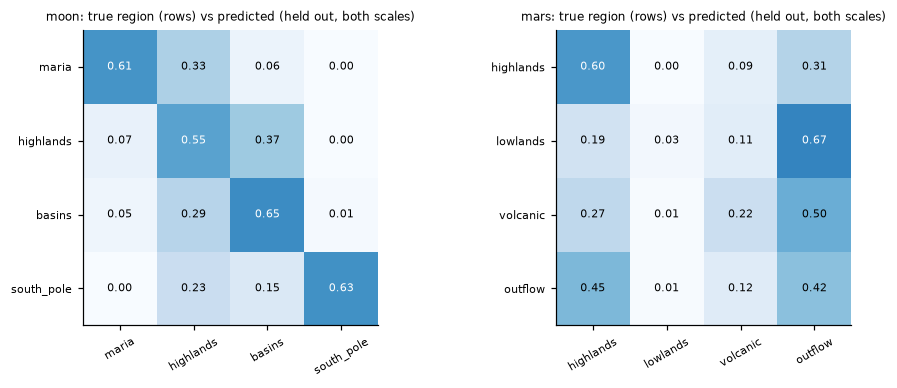

In [15]:
def to_logit_arr(score):
    return np.log(np.clip(score, 0.02, 0.98) / (1 - np.clip(score, 0.02, 0.98)))


XS = np.stack([to_logit_arr(oof[s][CHOSEN[s][0]]) for s in SCALES], axis=-1)       # (|Q|, 4, n_scales)
valid = ~np.isnan(XS).any(-1)
Y = (q_regs == q_region[:, None]).astype(int)


def fit_combo(mask):
    rows = valid & mask[:, None]
    return fit(np.c_[XS[rows], np.ones(rows.sum())], Y[rows], balanced(Y[rows]), np.zeros((len(SCALES) + 1,) * 2))


combo_cv = {n: [] for n in (*SCALES, "blend")}
blend_oof = np.full(XS.shape[:2], np.nan)
for f in range(CFG["folds"]):
    te = q_fold == f
    th = fit_combo(~te)
    blend_oof[te] = (XS[te] @ th[:-1]) + th[-1]
    combo_cv["blend"].append(region_accuracy(np.where(valid, blend_oof, np.nan), te)[0])
    for k, s in enumerate(SCALES):
        combo_cv[s].append(region_accuracy(np.where(valid, XS[..., k], np.nan), te)[0])
TH_COMBO = fit_combo(np.ones(len(Q), bool))
print("held-out region accuracy (chance 0.25):  " + "   ".join(f"{n} {np.mean(v):.3f} ± {np.std(v, ddof=1) / np.sqrt(len(v)):.3f}" for n, v in combo_cv.items()))
print("learned weights:", {s: round(float(TH_COMBO[k]), 2) for k, s in enumerate(SCALES)}, "bias", round(float(TH_COMBO[-1]), 2))
# The learned mix leans almost entirely on 32 km, which would make clicks a few km apart score nearly the same.
# So the 4 km scale gets a minimum share; the overall strength and the bias are refitted on the fixed mix.
w_l = np.maximum(TH_COMBO[:-1], 0.0)
k_site = SCALES.index("site")
if len(SCALES) > 1 and w_l.sum() > 0 and w_l[k_site] / w_l.sum() < CFG["site_share_min"]:
    mix = np.full(len(SCALES), (1 - CFG["site_share_min"]) / (len(SCALES) - 1)); mix[k_site] = CFG["site_share_min"]
    th1 = fit(np.c_[XS[valid] @ mix, np.ones(valid.sum())], Y[valid], balanced(Y[valid]), np.zeros((2, 2)))
    acc_mix = region_accuracy(np.where(valid, XS @ mix, np.nan), np.ones(len(Q), bool))[0]
    acc_learned = region_accuracy(np.where(valid, XS @ w_l, np.nan), np.ones(len(Q), bool))[0]
    TH_COMBO = np.r_[th1[0] * mix, th1[1]]
    print(f"4 km share raised from {w_l[k_site] / w_l.sum():.2f} to {CFG['site_share_min']:.2f}: region accuracy {acc_learned:.3f} -> {acc_mix:.3f}")
print("weights used:", {s: round(float(TH_COMBO[k]), 2) for k, s in enumerate(SCALES)}, "bias", round(float(TH_COMBO[-1]), 2))

pred_blend = q_regs[np.arange(len(Q)), np.nanargmax(np.where(np.isnan(blend_oof), -1e9, blend_oof), axis=1)]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, w in zip(axes, WORLDS):
    ids = world_regions[w]
    M = np.array([[np.mean(pred_blend[q_region == a] == b) for b in ids] for a in ids])
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
    names = [REGION_KEYS[r].split(":")[1] for r in ids]
    ax.set_xticks(range(len(ids)), names, rotation=30, fontsize=7); ax.set_yticks(range(len(ids)), names, fontsize=7)
    for (a, b), v in np.ndenumerate(M):
        ax.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.5 else "black")
    ax.set_title(f"{w}: true region (rows) vs predicted (held out, both scales)", fontsize=8)
plt.tight_layout(); plt.show()

site: final region M1, smoothness 1, 24000 triplets, 20 bootstrap refits (1s)


regional: final region M1, smoothness 1, 24000 triplets, 20 bootstrap refits (1s)


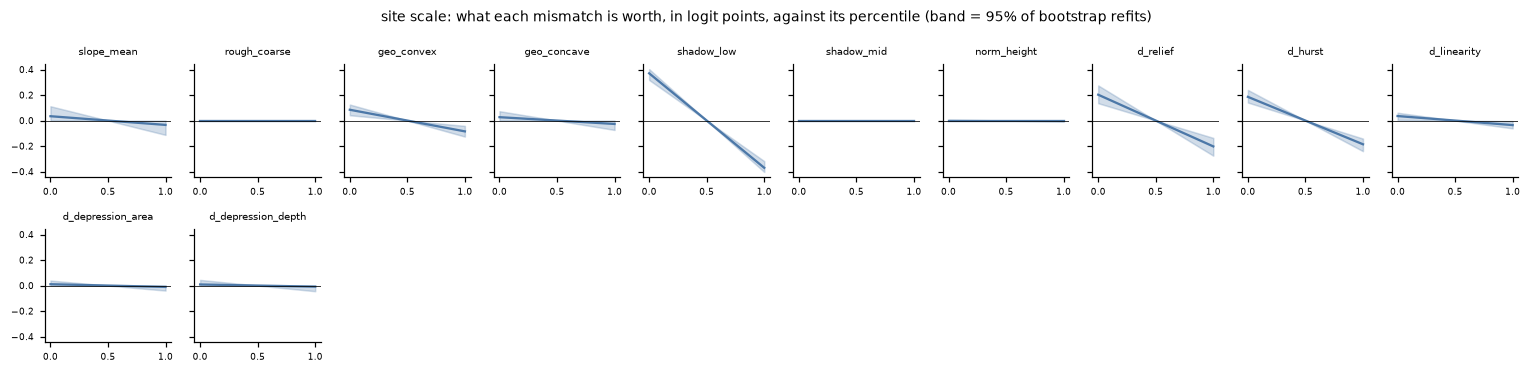

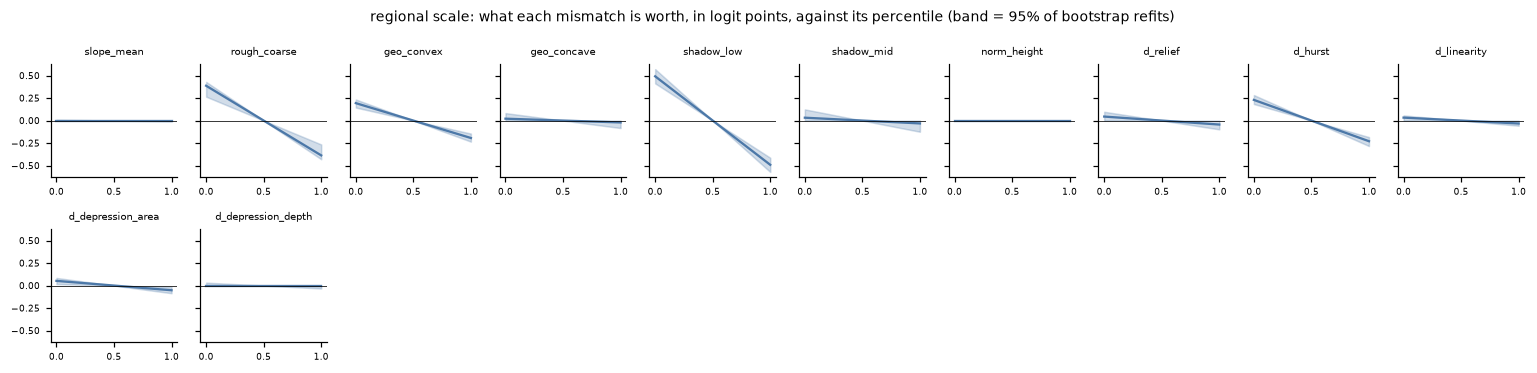

In [16]:
FINAL, FINAL_NOX, ENS = {}, {}, {}
rng_f = np.random.default_rng(SEED + 40)
t0 = time.time()
for s in SCALES:
    name, label, kind = CHOSEN[s]
    T = TR[(s, label)]
    lam = float(np.median(lam_pick[s][name]))
    allm = np.ones(len(T["is_cross"]), bool)
    FINAL[s] = train(s, label, kind, lam, allm)
    FINAL_NOX[s] = train(s, label, kind, lam, allm, use_cross=False)
    assert np.abs(FINAL[s][0]).max() > 0, f"the {s} pair model learned nothing: check the training rows"
    groups_u, gidx = np.unique(T["anchor_group"], return_inverse=True)
    curves_b, bias_b = [], []
    for _ in range(CFG["n_boot"]):
        mult = np.bincount(rng_f.integers(0, len(groups_u), len(groups_u)), minlength=len(groups_u))[gidx]
        c_, b_ = train(s, label, kind, lam, mult > 0, mult=mult)
        curves_b.append(c_); bias_b.append(b_)
    ENS[s] = (np.array(curves_b), np.array(bias_b))
    print(f"{s}: final {name}, smoothness {lam:g}, {len(allm)} triplets, {CFG['n_boot']} bootstrap refits ({time.time() - t0:.0f}s)")

for s in SCALES:
    fig, axes = plt.subplots(2, 10, figsize=(14, 3.4), sharey=True)
    for k, ax in enumerate(axes.flat):
        if k >= rt.N_IN:
            ax.axis("off"); continue
        lo, hi = np.percentile(ENS[s][0][:, k], [2.5, 97.5], axis=0)
        ax.fill_between(rt.GRID, lo, hi, color="#4c78a8", alpha=0.25)
        ax.plot(rt.GRID, FINAL[s][0][k], color="#4c78a8")
        ax.axhline(0, c="k", lw=0.5); ax.set_title(rt.INPUT_NAMES[k], fontsize=6.5); ax.tick_params(labelsize=6)
    fig.suptitle(f"{s} scale: what each mismatch is worth, in logit points, against its percentile (band = 95% of bootstrap refits)", fontsize=9)
    plt.tight_layout(); plt.show()

In [17]:
own_col = np.array([list(q_regs[i]).index(q_region[i]) for i in range(len(Q))])


def final_calibration(s, model_):
    A = aggregates(s, eval_logits(s, model_))
    own = A[np.arange(len(Q)), own_col]
    return A, [np.sort(own[(q_region == r) & ~np.isnan(own)]) for r in range(len(REGION_KEYS))]


def build_mz(models):
    w = np.maximum(TH_COMBO[:-1], 0.0)
    if w.sum() <= 0:
        w = np.r_[1.0, np.zeros(len(SCALES) - 1)]
    mz = dict(
        version=np.array(MODEL_VERSION), scales=np.array(SCALES),
        lib_world=lib["world"], lib_region=lib_region, lib_tag=lib_tag, lib_name=lib["name"],
        lib_lat=lib["lat"].astype(float), lib_lon=lib["lon"].astype(float), lib_href=lib["href"],
        region_keys=np.array(REGION_KEYS), region_title=np.array(REGION_TITLE),
        combo_bias=float(TH_COMBO[-1]), top_k=CFG["top_k"], shortlist=CFG["shortlist"],
        gate_names=np.array(rt.GATE_NAMES), gate_table=np.tile(rt.GRID, (len(rt.GATE_NAMES), 1)),
        gate_curve_vals=np.zeros((len(rt.GATE_NAMES), len(rt.GRID))), gate_bias=0.0,
        discount_floor=CFG["discount_floor"], precip_grid=PRECIP)
    r_o = np.random.default_rng(SEED + 50)
    for k, s in enumerate(SCALES):
        P = SC[s]
        es = P["earth_sk"][rand]
        es = es[r_o.choice(len(es), size=min(len(es), 3000), replace=False)]
        nn = ((es[:, None] - es[None]) ** 2).sum(-1)
        np.fill_diagonal(nn, np.inf)
        _, calib = final_calibration(s, models[s])
        mz.update({f"{s}__{a}": b for a, b in dict(
            scaler_scale=P["scale"], pca_mean=P["pca_mean"], pca_components=P["pca_comp"], pct_table=P["pct_table"],
            curve_vals=models[s][0], bias=models[s][1], ens_curve_vals=ENS[s][0], ens_bias=ENS[s][1],
            lib_tokens=P["lib_tok"].astype(np.float16), lib_block=P["lib_blk"], lib_sketch=P["lib_sk"].astype(np.float32),
            earth_sketch=es.astype(np.float32), ood_threshold=float(np.percentile(np.sqrt(nn.min(1)), 99)),
            combo_weight=float(w[k])).items()})
        mz.update({f"{s}__calib__{r}": (c if len(c) else np.array([0.0])) for r, c in enumerate(calib)})
    return mz


MZ = build_mz(FINAL)
model = rt.Model(MZ)
model_nox = rt.Model(build_mz(FINAL_NOX))


def earth_emb(i):
    return {s: (SC[s]["earth_tok"][i], SC[s]["earth_blk"][i], SC[s]["earth_sk"][i]) for s in SCALES}


def lib_emb(i):
    return {s: (SC[s]["lib_tok"][i], SC[s]["lib_blk"][i], SC[s]["lib_sk"][i]) for s in SCALES}


print("blend weights in the model:", {s: round(model.S[s]["weight"], 2) for s in SCALES},
      "| calibration blocks per region:", {REGION_KEYS[r]: len(model.calib["site"][r]) for r in range(len(REGION_KEYS))})

blend weights in the model: {'site': 0.18, 'regional': 0.27} | calibration blocks per region: {'moon:maria': 150, 'moon:highlands': 150, 'moon:basins': 150, 'moon:south_pole': 150, 'mars:highlands': 150, 'mars:lowlands': 150, 'mars:volcanic': 150, 'mars:outflow': 150}


In [18]:
# 1. Runtime agreement on a sample of evaluation blocks
A_fin = {s: final_calibration(s, FINAL[s])[0] for s in SCALES}
S_fin = np.stack([to_logit_arr(calibrated_scores(A_fin[s], np.ones(len(Q), bool), np.ones(len(Q), bool))) for s in SCALES], -1)
nb_pred = q_regs[np.arange(len(Q)), np.nanargmax(np.where(np.isnan(S_fin).any(-1), -1e9, S_fin @ np.maximum(TH_COMBO[:-1], 0)), axis=1)]
r_c = np.random.default_rng(SEED + 60)
pick = r_c.choice(len(Q), size=min(60, len(Q)), replace=False)
agree = [rt.region_scores(model, lib_emb(Q[i]), lib["world"][Q[i]], exclude=lib_group == lib_group[Q[i]], n_best=1)[0]["region_id"] == nb_pred[i]
         for i in pick]
print(f"runtime agreement: {np.mean(agree):.2f} of {len(pick)} blocks get the same top region from rt.region_scores as from the notebook")

# 2. Planet check, per scale: 5-nearest-neighbour guess of the world from the sketch (leave one out)
for s in SCALES:
    Sk = np.concatenate([SC[s]["lib_sk"], SC[s]["earth_sk"][rand]])
    lab = np.r_[lib["world"], np.array(["earth"] * rand.sum())]
    sub = r_c.choice(len(Sk), size=min(len(Sk), 3000), replace=False)
    D = ((Sk[sub][:, None] - Sk[sub][None]) ** 2).sum(-1)
    np.fill_diagonal(D, np.inf)
    guess = np.array([pd.Series(r).mode()[0] for r in lab[sub][np.argsort(D, axis=1)[:, :5]]])
    print(f"planet check, {s}: world guessed from the sketch {np.mean(guess == lab[sub]):.2f} of the time (chance 0.33)")

runtime agreement: 1.00 of 60 blocks get the same top region from rt.region_scores as from the notebook


planet check, site: world guessed from the sketch 0.65 of the time (chance 0.33)


planet check, regional: world guessed from the sketch 0.69 of the time (chance 0.33)


In [19]:
# Cross-world transfer. With cross_weight = 0 nothing was trained on these, so every crater and volcano is a test block.
# Only fairly bare blocks count: GLO-30 sees canopy and roofs, which isn't the landform.
VOLC_TAGS = ("volcanic_edifice", "lava_flow")
earth_cover = np.nansum([earth[g] for g in ("tree", "crop", "built", "water")], axis=0)


def cross_world(model_):
    rows = []
    sel = (earth["split"] == "test") & np.isin(earth["set"], ["crater", "volcano"]) & (earth_cover <= CFG["cover_max"])
    for i in np.flatnonzero(sel):
        world = "moon" if earth["set"][i] == "crater" else "mars"
        regs = rt.region_scores(model_, earth_emb(i), world, n_best=10)
        best = sorted((b for reg in regs for b in reg["best"]), key=lambda b: -b["logit"])[:10]
        if world == "moon":
            rows.append(dict(set="crater", name=earth["name"][i], value=np.mean([b["tag"] in CRATER_TAGS for b in best]), top=best[0]["tag"]))
        else:
            rows.append(dict(set="volcano", name=earth["name"][i], value=np.mean([b["tag"] in VOLC_TAGS for b in best]),
                             region=float(regs[0]["region"] == "mars:volcanic"), top=regs[0]["region"]))
    return pd.DataFrame(rows)


base_c = np.mean(np.isin(lib_tag[world_idx["moon"]], CRATER_TAGS))
base_v = np.mean(np.isin(lib_tag[world_idx["mars"]], VOLC_TAGS))
runs = [("shipped model", cross_world(model))] + ([("without cross-world triplets", cross_world(model_nox))] if CFG["cross_weight"] > 0 else [])
for name, d in runs:
    c, v = d[d.set == "crater"], d[d.set == "volcano"]
    print(f"{name:30s} Earth craters: {c.value.mean():.2f} of the 10 best Moon matches are crater-tagged (base rate {base_c:.2f}, n={len(c)})   "
          f"Earth volcanoes: {v.value.mean():.2f} of the 10 best Mars matches are volcano or lava-flow tagged (base rate {base_v:.2f}), "
          f"top region volcanic {v.region.mean():.2f} (chance 0.25, n={len(v)})")
xw = runs[0][1]
xw.groupby("set").head(8)

shipped model                  Earth craters: 0.18 of the 10 best Moon matches are crater-tagged (base rate 0.19, n=31)   Earth volcanoes: 0.05 of the 10 best Mars matches are volcano or lava-flow tagged (base rate 0.05), top region volcanic 0.09 (chance 0.25, n=119)


,set,name,value,top,region
0,crater,Aorounga rim,0.5,graben,NaN
1,crater,Aorounga rim,0.2,wrinkle_ridge,NaN
2,crater,Aorounga rim,0.4,crater_chain,NaN
3,crater,Araguainha rim,0.3,graben,NaN
4,crater,Barringer (= Meteor),0.1,background,NaN
5,crater,Eagle Butte rim,0.0,wrinkle_ridge,NaN
6,crater,Eagle Butte rim,0.0,wrinkle_ridge,NaN
7,crater,Eagle Butte rim,0.1,background,NaN
31,volcano,Andahua-Orcopampa,0.0,mars:outflow,0.0
32,volcano,Jordan Craters,0.0,mars:outflow,0.0


region logits for 2902 Earth blocks in 153s; best-region logit, 5/50/95%: [-0.82  0.52  1.47]
held-out analog sites, rank among held-out random land (0% = top, 50% = chance):
  landscape only   median  71.7%   in the top 10%: 0.04   n=69
  conditions only  median  26.8%   in the top 10%: 0.04   n=69
  overall          median  29.6%   in the top 10%: 0.07   n=69
overall = landscape x (0.0 + 1.0 x conditions/100)


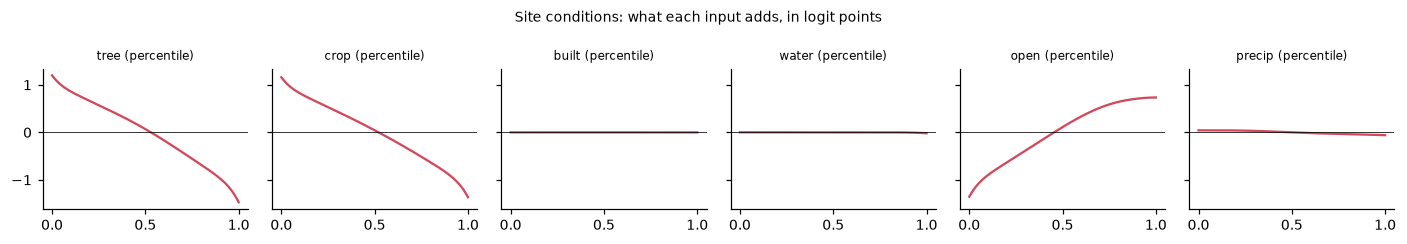

In [20]:
t0 = time.time()
gsel = np.flatnonzero(np.isin(earth["set"], ["analog", "random"]))
feat_idx = np.flatnonzero(earth["set"] == "featured")
# every Earth block is scored once, in parallel, and saved, so diag.ipynb doesn't have to score them again
tmp_model = CACHE / f"model_tmp_{PROFILE}.npz"
np.savez(tmp_model, **MZ)
with ProcessPoolExecutor(CFG["score_workers"]) as ex:
    scored = list(ex.map(rt.region_logits_task, [(str(tmp_model), earth_emb(i)) for i in range(len(earth["set"]))], chunksize=16))
EL, EL_SCALE = np.stack([o[0] for o in scored]), np.stack([o[1] for o in scored])
np.savez_compressed(CACHE / f"earth_scores_{PROFILE}_{CACHE_TAG}.npz", logit=EL, per_scale=EL_SCALE, name=earth["name"], set=earth["set"],
                    lat=earth["lat"], lon=earth["lon"], regions=np.array(REGION_KEYS), scales=np.array(SCALES))
tmp_model.unlink()
T_all = np.nanmax(np.where(np.isnan(EL), -np.inf, EL), axis=1)
print(f"region logits for {len(EL)} Earth blocks in {time.time() - t0:.0f}s; "
      f"best-region logit, 5/50/95%: {np.percentile(T_all[gsel], [5, 50, 95]).round(2)}")

# inputs: tree, crop, built, water, open (bare ground + snow and ice), rainfall. only "open" can raise the score
GATE_SIGNS = (-1.0, -1.0, -1.0, -1.0, +1.0, -1.0)
antarctic = (earth["lat"] < -60) & np.isnan(earth["bare"])          # blocks cached before the readers knew about Antarctica
env_rows = [dict(tree=0.0, crop=0.0, built=0.0, water=0.0, snow=1.0, bare=0.0, precip=earth["precip"][i]) if antarctic[i]
            else {g: earth[g][i] for g in rt.ENV_NAMES} for i in range(len(earth["set"]))]
ENV = np.stack([rt.gate_inputs(e) for e in env_rows])
gate_table = np.stack([np.quantile(ENV[rand, m][~np.isnan(ENV[rand, m])], rt.GRID) for m in range(ENV.shape[1])])
Zg = rt.to_z(gate_table, np.nan_to_num(ENV))
Zg[np.isnan(ENV)] = 0.5
yg, Zs, Tg, gg = (earth["set"][gsel] == "analog").astype(int), Zg[gsel], T_all[gsel], earth_group[gsel]
GLAM = (1.0, 1e-2)


def gate_fit(Z, y):
    return fit(design(Z, GATE_SIGNS, "M2"), y, balanced(y), penalty(len(GATE_SIGNS), "M2", *GLAM))


def rank_pct(pos, neg):
    return 100.0 * (len(neg) - np.searchsorted(np.sort(neg), pos, side="left")) / len(neg)


gf = group_folds(gg, 5, SEED + 70)
G_oof = np.zeros(len(yg))
for f in range(5):
    G_oof[gf == f] = design(Zs[gf == f], GATE_SIGNS, "M2") @ gate_fit(Zs[gf != f], yg[gf != f])
# v1.1: no learned blend. overall = best landscape score x discount, discount = floor + (1 - floor) x conditions
disc_oof = CFG["discount_floor"] + (1 - CFG["discount_floor"]) * expit(G_oof)
B_oof = 100 * expit(Tg) * disc_oof
print("held-out analog sites, rank among held-out random land (0% = top, 50% = chance):")
for name, v in (("landscape only", Tg), ("conditions only", G_oof), ("overall", B_oof)):
    r = np.concatenate([rank_pct(v[(gf == f) & (yg == 1)], v[(gf == f) & (yg == 0)]) for f in range(5) if ((gf == f) & (yg == 1)).any()])
    print(f"  {name:16s} median {np.median(r):5.1f}%   in the top 10%: {np.mean(r <= 10):.2f}   n={len(r)}")

th_g = gate_fit(Zs, yg)
nc = BASIS.n_cols
g_curves = np.array([s * (GRID_I @ th_g[m * nc:(m + 1) * nc]) for m, s in enumerate(GATE_SIGNS)])
g_centres = g_curves.mean(1)
MZ.update(gate_table=gate_table, gate_curve_vals=g_curves - g_centres[:, None], gate_bias=float(th_g[-1] + g_centres.sum()),
          discount_floor=CFG["discount_floor"])
model = rt.Model(MZ)
print(f"overall = landscape x ({model.discount_floor:.1f} + {1 - model.discount_floor:.1f} x conditions/100)")

fig, axes = plt.subplots(1, len(rt.GATE_NAMES), figsize=(13, 2.2), sharey=True)
for m, ax in enumerate(axes):
    ax.plot(rt.GRID, model.gate_curve[m], color="#d1495b"); ax.axhline(0, c="k", lw=0.5)
    ax.set_title(f"{rt.GATE_NAMES[m]} (percentile)", fontsize=8)
plt.suptitle("Site conditions: what each input adds, in logit points", fontsize=9)
plt.tight_layout(); plt.show()

In [21]:
def stored_click(i):
    k = int(np.searchsorted(earth["dem_index"], i))
    return ({"site": earth["dem_site"][k].astype(float), "regional": earth["dem_regional"][k].astype(float)},
            {n: float(v) for n, v in env_rows[i].items()})


rows = []
for i in feat_idx:
    r = rt.score_click(model, *stored_click(i))
    row = dict(site=earth["name"][i], expected=int(earth["expected"][i]), conditions=round(r["conditions"]["score"]))
    for w in WORLDS:
        top = r["worlds"][w]["regions"][0]
        row[f"{w}_region"], row[f"{w}_landscape"], row[f"{w}_overall"] = top["region"].split(":")[1], round(top["score"]), round(top["overall"])
    rows.append(row)
feat = pd.DataFrame(rows).sort_values("expected")
print(f"Spearman with the expected order: conditions {spearmanr(feat.expected, feat.conditions).statistic:.2f}, "
      + ", ".join(f"{w} overall {spearmanr(feat.expected, feat[f'{w}_overall']).statistic:.2f}" for w in WORLDS))
feat

Spearman with the expected order: conditions 0.48, moon overall 0.56, mars overall 0.50


,site,expected,conditions,moon_region,moon_landscape,moon_overall,mars_region,mars_landscape,mars_overall
0,Dutch farmland,1,24,maria,40,10,volcanic,42,10
1,Amazon rainforest,1,9,maria,49,4,volcanic,61,5
2,Himalayan ridge,2,69,highlands,20,14,highlands,24,17
3,Utah near MDRS,3,69,highlands,50,35,outflow,51,35
4,Holuhraun lava field,4,68,highlands,69,47,highlands,67,46
5,Lanzarote Timanfaya,5,65,highlands,49,31,outflow,47,30
6,Meteor Crater,5,66,maria,60,40,outflow,53,35
7,Haughton crater,6,68,maria,43,29,outflow,46,32
8,McMurdo Dry Valleys,6,71,basins,50,35,outflow,37,26


In [22]:
model_path = EXPORT / "model.npz"
np.savez_compressed(model_path, **MZ)
np.savez_compressed(EXPORT / "regions.npz", moon=REGION_GRID["moon"], mars=REGION_GRID["mars"], res_deg=RES_DEG,
                    keys=np.array(REGION_KEYS), titles=np.array(REGION_TITLE), excluded=EXCLUDED)
i_mc = int(np.flatnonzero(earth["name"] == "Meteor Crater")[0])
dems_mc, env_mc = stored_click(i_mc)
np.savez(CACHE / "test_click_meteor.npz", **dems_mc)
(CACHE / "test_env_meteor.json").write_text(json.dumps(env_mc))

model = rt.load(model_path)
here = rt.score_click(model, dems_mc, env_mc)

probe = f'''
import json, sys, time, numpy as np
sys.path.insert(0, {str(EXPORT)!r})
import analog_runtime as rt
m = rt.load({str(model_path)!r})
d = np.load({str(CACHE / "test_click_meteor.npz")!r})
env = json.loads(open({str(CACHE / "test_env_meteor.json")!r}).read())
t = time.time()
r = rt.score_click(m, {{k: d[k] for k in d.files}}, env)
ms = 1000 * (time.time() - t)
heavy = [k for k in ("rasterio", "pandas", "pyproj", "sklearn", "torch") if k in sys.modules]
print(json.dumps({{w: [r["worlds"][w]["landscape_score"], r["worlds"][w]["best_match"]["name"]] for w in r["worlds"]}} | {{"ms": ms, "heavy": heavy}}))
'''
there = json.loads(subprocess.run([sys.executable, "-I", "-c", probe], capture_output=True, text=True, check=True).stdout)
for w in WORLDS:
    assert abs(there[w][0] - here["worlds"][w]["landscape_score"]) < 1e-9 and there[w][1] == here["worlds"][w]["best_match"]["name"]
assert not there["heavy"], there["heavy"]
print(f"round trip OK. model.npz = {model_path.stat().st_size / 1e6:.1f} MB for {N_LIB} library locations; "
      f"score_click = {there['ms']:.0f} ms in a fresh process (excluding the reads)")

CHECK_LIVE = False      # True: also time one live GLO-30 + WorldCover read through analog_readers
if CHECK_LIVE:
    t0 = time.time()
    dems_live, env_live = rd.fetch_earth(model, 35.027, -111.022)
    t_fetch = time.time() - t0
    live = rt.score_click(model, dems_live, env_live)
    print(f"live path: fetch {t_fetch:.1f}s (GLO-30 at two scales + WorldCover) + score {time.time() - t0 - t_fetch:.1f}s; "
          + ", ".join(f"{w} landscape {live['worlds'][w]['landscape_score']:.0f} (stored windows: {here['worlds'][w]['landscape_score']:.0f})" for w in WORLDS))


def jsonable(o):
    if isinstance(o, dict):
        return {k: jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, (float, np.floating)):
        return None if not np.isfinite(o) else round(float(o), 4)
    return o.item() if isinstance(o, np.generic) else o


(EXPORT / "example_response.json").write_text(json.dumps(jsonable(here), indent=1))
print("wrote", [p.name for p in sorted(EXPORT.glob("*")) if p.is_file()])

round trip OK. model.npz = 11.3 MB for 4636 library locations; score_click = 390 ms in a fresh process (excluding the reads)
wrote ['analog_readers.py', 'analog_runtime.py', 'example_response.json', 'model.npz', 'regions.npz']


SITE CONDITIONS 66/100   tree +0.40  crop -0.16  built +0.00  water +0.00  open +0.59  precip +0.03

MOON TAB   best region: moon:maria   best single site: lunar maria, 87 km from Ulugh Beigh B (pair score 69)
   Lunar maria                      landscape  60.2  overall  39.8   [site 13, regional 88]   best: lunar maria, 87 km from Ulugh Beigh B [background] (32.27, -75.97)
   Lunar highlands                  landscape  22.8  overall  15.1   [site 4, regional 4]   best: sinuous rille, 27 km from Galilaei L [sinuous_rille] (12.80, -57.81)
   Impact basin rings and ejecta    landscape  18.4  overall  12.1   [site 1, regional 0]   best: impact basin rings and ejecta, 37 km from Ukert W [background] (10.62, 1.86)
   South polar region               landscape  18.4  overall  12.1   [site 0, regional 0]   best: south polar region, 47 km from Idel'son L [background] (-85.26, 128.44)

MARS TAB   best region: mars:outflow   best single site: northern lowlands, 112 km from Mastung (pair score 67

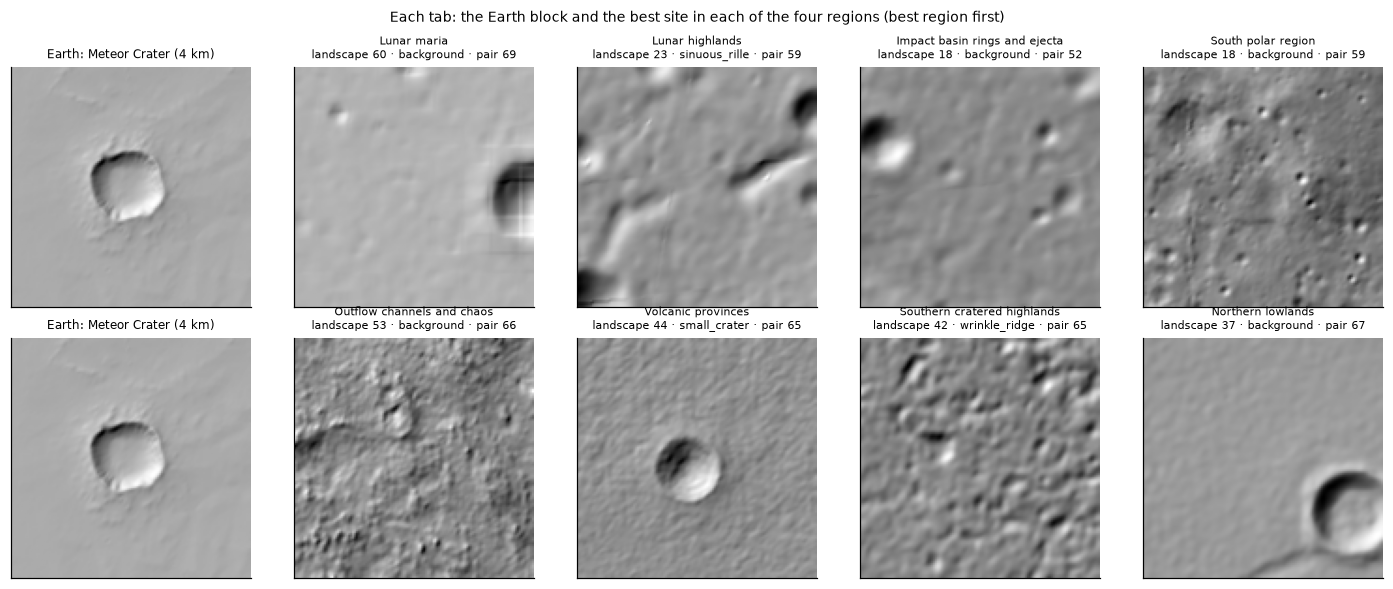

In [23]:
res = here
c = res["conditions"]
print(f"SITE CONDITIONS {c['score']:.0f}/100   " + "  ".join(f"{k} {v:+.2f}" for k, v in c["terms"].items()))
for w in WORLDS:
    r = res["worlds"][w]
    print(f"\n{w.upper()} TAB   best region: {r['best_region']}   best single site: {r['best_match']['name']} (pair score {r['best_match']['pair_score']:.0f})")
    for reg in r["regions"]:
        b = reg["best"][0]
        print(f"   {reg['title']:32s} landscape {reg['score']:5.1f}  overall {reg['overall']:5.1f}   "
              f"[site {reg['scales']['site']['score']:.0f}, regional {reg['scales'].get('regional', {}).get('score', float('nan')):.0f}]   "
              f"best: {b['name']} [{b['tag']}] ({b['lat']:.2f}, {b['lon']:.2f})")

pad = slice(rt.PAD_PX, -rt.PAD_PX)
fig, axes = plt.subplots(2, 5, figsize=(13, 5.4))
for row, w in enumerate(WORLDS):
    axes[row, 0].imshow(hillshade(dems_mc["site"][pad, pad]), cmap="gray")
    axes[row, 0].set_title("Earth: Meteor Crater (4 km)", fontsize=8)
    for ax, reg in zip(axes[row, 1:], res["worlds"][w]["regions"]):
        b = reg["best"][0]
        ax.imshow(hillshade(lib["dem_site"][b["index"]].astype(float)), cmap="gray")
        ax.set_title(f"{reg['title']}\nlandscape {reg['score']:.0f} · {b['tag']} · pair {b['pair_score']:.0f}", fontsize=7)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Each tab: the Earth block and the best site in each of the four regions (best region first)", fontsize=9)
plt.tight_layout(); plt.show()